# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [995]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from IPython.display import display
import plotly.express as px
from scipy import stats


pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

DATA_DIR = Path("data\\S04")
RAW_CLIENTS = DATA_DIR / "clients.csv"
RAW_TXN = DATA_DIR / "transactions.csv"


## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [996]:
clients_date_cols = ['birth_date', 'registration_date', 'card_open_date', 'app_last_login']

clients_df = pd.read_csv(
    RAW_CLIENTS, 
    encoding="utf-8", 
    sep=",", 
    decimal=".", 
    parse_dates=clients_date_cols, 
    date_format={
        'birth_date': '%Y-%m-%d',
        'registration_date': '%d.%m.%Y',
        'card_open_date': '%d.%m.%Y',
        'app_last_login': '%Y-%m',
        },
    dtype={
        'branch_code': 'str',
    }
    )
clients_df.head()

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004616,1949-02-02,Ж,казань,Зарплатный,Серебро,Дебетовая,2020-12-18,2021-07-26,Зарплата в нашем банке,90700.0,Да,2024-09-01,4.0,00261,Да
1,C005737,1966-08-21,Ж,г. Москва,Массовый,Платина,Дебетовая,2013-05-08,2018-02-13,Зарплата в другом банке,42200.0,Да,2024-03-01,4.0,00307,Да
2,C003486,1995-08-01,Ж,Екатеринбург,Зарплатный,Базовый,Дебетовая,2019-11-08,2022-10-21,Зарплата в нашем банке,33700.0,Да,2024-08-01,NaN,00557,Да
3,C004080,1964-05-25,Ж,г. Москва,Зарплатный,Серебро,Дебетовая,2019-02-09,2022-12-12,Зарплата в нашем банке,80200.0,Да,2024-10-01,2.0,00560,Да
4,C001644,1978-07-11,Ж,Москва,Массовый,Базовый,Кредитная,2017-07-28,2018-07-19,Не указан,66500.0,Нет,NaT,NaN,00236,Да


In [997]:
txns_df = pd.read_csv(
    RAW_TXN, 
    encoding="windows-1251", 
    sep=";", 
    decimal=","
    )
txns_df['txn_datetime'] = pd.to_datetime(txns_df['txn_datetime'], format='mixed')
txns_df.head()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990047,C000099,2023-12-03 07:08:38,-484.78,RUB,Продукты,5411,Карта,возврат
1,990174,C002675,2023-12-18 22:01:45,1229.59,RUB,Развлечения и досуг,7832,Карта,успешно
2,990095,C003943,2023-12-19 13:21:05,59.01,RUB,Транспорт,4111,Карта,успешно
3,990201,C003454,2023-12-28 16:01:33,397.66,RUB,Связь и Интернет,4814,Онлайн-банк,успешно
4,990101,C002103,2023-12-30 13:20:11,5649.57,RUB,Кафе и рестораны,5812,Онлайн-банк,успешно


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [998]:
clients_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5666 entries, 0 to 5665
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5666 non-null   str           
 1   birth_date          5666 non-null   datetime64[us]
 2   gender              5666 non-null   str           
 3   city                5666 non-null   str           
 4   segment             5666 non-null   str           
 5   loyalty_tier        5666 non-null   str           
 6   card_type           5666 non-null   str           
 7   registration_date   5666 non-null   datetime64[us]
 8   card_open_date      5666 non-null   datetime64[us]
 9   income_source       5666 non-null   str           
 10  monthly_income      5134 non-null   float64       
 11  has_mobile_app      5666 non-null   str           
 12  app_last_login      3517 non-null   datetime64[us]
 13  satisfaction_score  2326 non-null   float64       
 14  bra

In [999]:
total_rows = clients_df.shape[0]
missing_values = clients_df.isna().sum()
missing_percentage = round((missing_values / total_rows) * 100, 2)
missing_clients_df = pd.DataFrame({
    'Записей': total_rows,
    'Пропущено, кол-во': missing_values,
    'Пропущено, %': missing_percentage
})
missing_clients_df = missing_clients_df.loc[missing_clients_df['Пропущено, кол-во'] > 0]
missing_clients_df

,Записей,"Пропущено, кол-во","Пропущено, %"
monthly_income,5666,532,9.39
app_last_login,5666,2149,37.93
satisfaction_score,5666,3340,58.95


В `clients_df` единица наблюдения - отдельный клиент.
Типы столбцов соответствуют ожиданию исходя из их смысла. Можно расмотреть изменение типа столбца `gender` на бинарный. Столбцы `has_mobile_app` и `marketing_opt_in` по смыслу являютя boolen - можно в дальнейшем расмотреть необходимость их преобразования к этому типу. `branch_code` сделан str намерено, чтобы не терять нули в начале кода. В `app_last_login` и `satisfaction_score` заметно много пропусков. Так же есть проспуски в `monthly_income`

In [1000]:
txns_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 618422 entries, 0 to 618421
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        618422 non-null  int64         
 1   client_id     618422 non-null  str           
 2   txn_datetime  618422 non-null  datetime64[us]
 3   amount        618422 non-null  float64       
 4   currency      618422 non-null  str           
 5   category      618422 non-null  str           
 6   mcc_code      618422 non-null  int64         
 7   channel       618422 non-null  str           
 8   status        618422 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(5)
memory usage: 42.5 MB


В  `txns_df` единица наблюдения - отдельная транзакция конкретного клиента. Все столбцы полные (стоит перепровериь наличие "заглушек"). Типы столбцов соответствуют ожиданию исходя из их смысла.

Можно предположить, что таблицы связаны по ключу `client_id` (далее проверим эту гипотезу).

### 2.2. Дубли

In [1001]:
full_clients_dup = clients_df.duplicated().sum()
clients_id_dup = len(clients_df[(clients_df['client_id'].duplicated()) & ~(clients_df.duplicated())])

print(f'Количество полных дубликатов строк в таблице clients_df: {full_clients_dup}')
print(f'Количество дубликатов клиентов (не учитывая полные дубликаты) в таблице clients_df: {clients_id_dup}')

Количество полных дубликатов строк в таблице clients_df: 41
Количество дубликатов клиентов (не учитывая полные дубликаты) в таблице clients_df: 14


In [1002]:
clients_df[(clients_df['client_id'].duplicated(keep=False)) & ~(clients_df.duplicated(keep=False))].sort_values(by='client_id')

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
3173,C000105,1955-11-18,М,Новосибирск,Премиальный,Серебро,Кредитная,2017-09-17,2020-10-25,Зарплата в нашем банке,106300.0,Нет,NaT,NaN,00585,Нет
4503,C000105,1955-11-18,М,Москва,Зарплатный,Серебро,Кредитная,2017-09-17,2020-10-25,Зарплата в нашем банке,106300.0,Нет,NaT,NaN,00585,Нет
4110,C000192,1962-01-28,Ж,г. Санкт-Петербург,Private,Платина,Дебетовая,2018-07-14,2021-10-31,Не указан,412300.0,Нет,NaT,4.0,00825,Да
3583,C000192,1962-01-28,Ж,Санкт-Петербург,Массовый,Платина,Дебетовая,2018-07-14,2021-10-31,Не указан,412300.0,Нет,NaT,4.0,00825,Да
4636,C000264,1990-09-22,Ж,Москва,Премиальный,Серебро,Кредитная,2016-04-20,2021-05-13,Зарплата в нашем банке,190.6,Нет,NaT,NaN,00702,Да
1909,C000264,1990-09-22,Ж,Новосибирск,Private,Серебро,Кредитная,2016-04-20,2021-05-13,Зарплата в нашем банке,190.6,Нет,NaT,NaN,00702,Да
1913,C000537,1979-03-27,Ж,Санкт-Петербург,Массовый,Базовый,Дебетовая,2017-06-01,2019-04-09,Зарплата в нашем банке,65200.0,Да,2024-10-01,NaN,00200,Да
1952,C000537,1979-03-27,Ж,Санкт-Петербург,Премиальный,Базовый,Дебетовая,2017-06-01,2019-04-09,Зарплата в нашем банке,65200.0,Да,2024-10-01,NaN,00200,Да
4511,C000713,1971-11-20,М,Санкт-Петербург,Массовый,Базовый,Дебетовая,2012-07-19,2016-11-30,Зарплата в другом банке,98800.0,Нет,NaT,NaN,00289,Да
1459,C000713,1971-11-20,М,Санкт-Петербург,Зарплатный,Базовый,Дебетовая,2012-07-19,2016-11-30,Зарплата в другом банке,98800.0,Нет,NaT,NaN,00289,Да


Есть разные виды дублей по `client_id`. Часть дублей появилась из-за отсутствия единого написания городов. Часть дублей из-за разной информации об одном и томе же клиенте (разные города или принадлежность к сегменту)

In [1003]:
full_txn_dup = txns_df.duplicated().sum()
txn_id_dup = len(txns_df[(txns_df['txn_id'].duplicated()) & ~(txns_df.duplicated())])
print(f'Количество полных дубликатов строк в таблице txns_df: {full_txn_dup}')
print(f'Количество дубликатов транзакций (не учитывая полные дубликаты) в таблице txns_df: {txn_id_dup}')

Количество полных дубликатов строк в таблице txns_df: 1282
Количество дубликатов транзакций (не учитывая полные дубликаты) в таблице txns_df: 218


In [1004]:
txns_df[(txns_df['txn_id'].duplicated(keep=False)) & ~(txns_df.duplicated(keep=False))].sort_values(by='txn_id').head(30)

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
1890,101880,C005121,2024-01-03 00:00:00,1605.54,RUB,Связь и Интернет,4814,Онлайн-банк,успешно
1891,101880,C005121,2024-01-03 15:50:29,1605.54,RUB,Связь и Интернет,4814,Онлайн-банк,успешно
2150,102139,C000793,2024-01-03 23:49:42,98.01,RUB,Транспорт,4111,Карта,успешно
2151,102139,C000793,2024-01-03 00:00:00,98.01,RUB,Транспорт,4111,Карта,успешно
3641,103628,C001198,2024-01-05 00:00:00,324.72,RUB,Транспорт,4111,Карта,успешно
3642,103628,C001198,2024-01-05 14:33:32,324.72,RUB,Транспорт,4111,Карта,успешно
4212,104196,C001496,2024-01-05 00:00:00,1280.39,RUB,Продукты,5411,Карта,успешно
4213,104196,C001496,2024-01-05 20:49:49,1280.39,RUB,Продукты,5411,Карта,успешно
7548,107519,C002528,2024-01-09 00:00:00,1778.72,RUB,АЗС,5541,Токен,успешно
7549,107519,C002528,2024-01-09 06:57:34,1778.72,RUB,АЗС,5541,Токен,успешно


Неполные дубликаты по txn_id по всей видимости связаны с тем, что есть транзакции, без указания точного времени транзакции, которые дублируют транзакции с точным временем.

### 2.3. Соответствие данных описанию полей из задания

### `clients.csv` — справочник действующих клиентов на 30.06.2025

| поле | описание |
|---|---|
| `client_id` | идентификатор клиента |
| `birth_date` | дата рождения |
| `gender` | пол |
| `city` | город проживания |
| `segment` | сегмент: Массовый, Зарплатный, Премиальный, Private |
| `loyalty_tier` | уровень лояльности: Базовый, Серебро, Золото, Платина |
| `card_type` | тип карты: Дебетовая, Кредитная, Премиальная |
| `registration_date` | дата прихода клиента в банк |
| `card_open_date` | дата открытия текущей карты |
| `income_source` | источник зарплаты со слов клиента |
| `monthly_income` | ежемесячный доход, рублей |
| `has_mobile_app` | установлено ли мобильное приложение |
| `app_last_login` | месяц последнего входа в приложение |
| `satisfaction_score` | оценка качества обслуживания по опросу, от 1 до 5 |
| `branch_code` | код отделения обслуживания |
| `marketing_opt_in` | согласие на маркетинговую коммуникацию |

In [1005]:
clients_df.head()

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C004616,1949-02-02,Ж,казань,Зарплатный,Серебро,Дебетовая,2020-12-18,2021-07-26,Зарплата в нашем банке,90700.0,Да,2024-09-01,4.0,00261,Да
1,C005737,1966-08-21,Ж,г. Москва,Массовый,Платина,Дебетовая,2013-05-08,2018-02-13,Зарплата в другом банке,42200.0,Да,2024-03-01,4.0,00307,Да
2,C003486,1995-08-01,Ж,Екатеринбург,Зарплатный,Базовый,Дебетовая,2019-11-08,2022-10-21,Зарплата в нашем банке,33700.0,Да,2024-08-01,NaN,00557,Да
3,C004080,1964-05-25,Ж,г. Москва,Зарплатный,Серебро,Дебетовая,2019-02-09,2022-12-12,Зарплата в нашем банке,80200.0,Да,2024-10-01,2.0,00560,Да
4,C001644,1978-07-11,Ж,Москва,Массовый,Базовый,Кредитная,2017-07-28,2018-07-19,Не указан,66500.0,Нет,NaT,NaN,00236,Да


In [1006]:
check_cols = ['gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'income_source', 'has_mobile_app', 'satisfaction_score', 'marketing_opt_in']

for col in check_cols:
    print(clients_df[col].value_counts(), '\n')

gender
Ж    2850
М    2816
Name: count, dtype: int64 

city
Москва                1036
Новосибирск            745
Санкт-Петербург        657
Казань                 563
Нижний Новгород        530
Екатеринбург           505
г. Новосибирск         235
г. Москва              198
МОСКВА                 174
казань                 172
 москва                170
Н. Новгород            168
СПб                    119
ЕКАТЕРИНБУРГ           115
г. Санкт-Петербург     103
г.Екатеринбург          97
Санкт Петербург         79
Name: count, dtype: int64 

segment
Массовый       2938
Зарплатный     1537
Премиальный     939
Private         252
Name: count, dtype: int64 

loyalty_tier
Базовый    2872
Серебро    1487
Золото      972
Платина     335
Name: count, dtype: int64 

card_type
Дебетовая      3944
Кредитная      1210
Премиальная     512
Name: count, dtype: int64 

income_source
Зарплата в нашем банке     2565
Не указан                  1564
Зарплата в другом банке    1537
Name: count, dtype: int6

Данные поля соответствуют описанию данных. Нужно унифицировать названия городов.

In [1007]:
clients_df.describe()

,birth_date,registration_date,card_open_date,monthly_income,app_last_login,satisfaction_score
count,5666,5666,5666,5134.000000,3517,2326.000000
mean,1971-11-26 21:56:59.555241,2017-09-08 09:09:58.517472,2020-09-16 18:53:45.132368,96067.320530,2024-09-19 01:36:37.668467,3.332330
min,1936-07-23 00:00:00,2010-01-08 00:00:00,2016-01-01 00:00:00,-999.000000,2024-01-01 00:00:00,1.000000
25%,1963-02-03 12:00:00,2015-04-04 06:00:00,2018-04-08 00:00:00,52600.000000,2024-05-01 00:00:00,2.000000
50%,1973-10-22 12:00:00,2017-08-08 00:00:00,2020-09-01 12:00:00,73650.000000,2024-10-01 00:00:00,3.000000
75%,1982-07-07 18:00:00,2020-01-30 00:00:00,2023-01-07 00:00:00,109000.000000,2025-02-01 00:00:00,5.000000
max,2003-08-28 00:00:00,2025-04-27 00:00:00,2025-05-16 00:00:00,865400.000000,2025-06-01 00:00:00,5.000000
std,NaN,NaN,NaN,81531.834263,NaN,1.378812


Дат больше 30.06.2025 нет. Значит справочник выгружен раньше, как и сказано в описании данных. `satisfaction_score` от 1 до 5 как и заявлялось. На первый взгляд поля в `clients_df` соответсетствуют описанию данных. В дальнейшем посмотрим на распределение, чтобы окончательно в этом убедиться.

### `transactions.csv` — операции по картам

| поле | описание |
|---|---|
| `txn_id` | идентификатор операции |
| `client_id` | идентификатор клиента |
| `txn_datetime` | дата и время операции |
| `amount` | сумма операции |
| `currency` | валюта операции |
| `category` | категория траты, одна из девяти |
| `mcc_code` | код типа торговой точки, соответствует категории |
| `channel` | способ оплаты: Карта, Токен, СБП, Онлайн-банк |
| `status` | статус операции: успешно, отклонено, возврат |

In [1008]:
txns_df.head()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990047,C000099,2023-12-03 07:08:38,-484.78,RUB,Продукты,5411,Карта,возврат
1,990174,C002675,2023-12-18 22:01:45,1229.59,RUB,Развлечения и досуг,7832,Карта,успешно
2,990095,C003943,2023-12-19 13:21:05,59.01,RUB,Транспорт,4111,Карта,успешно
3,990201,C003454,2023-12-28 16:01:33,397.66,RUB,Связь и Интернет,4814,Онлайн-банк,успешно
4,990101,C002103,2023-12-30 13:20:11,5649.57,RUB,Кафе и рестораны,5812,Онлайн-банк,успешно


In [1009]:
check_cols = ['currency', 'category', 'mcc_code', 'channel', 'status']

for col in check_cols:
    print(txns_df[col].value_counts(), '\n')

currency
RUB    615954
EUR      1260
USD      1208
Name: count, dtype: int64 

category
Продукты               162745
Транспорт               64812
Одежда и обувь          63831
АЗС                     56759
Развлечения и досуг     53572
Кафе и рестораны        47963
Аптеки                  45030
Онлайн-сервисы          43110
Связь и интернет        29175
Связь и Интернет        19287
кафе и рестораны        16092
Кафе/рестораны          16046
Name: count, dtype: int64 

mcc_code
5411    162465
5812     80082
4111     64825
5651     63874
5541     56802
7832     53631
4814     48493
5912     45081
5815     43169
Name: count, dtype: int64 

channel
Карта          312869
СБП            115882
Токен          103749
Онлайн-банк     85922
Name: count, dtype: int64 

status
успешно      598723
отклонено     12340
возврат        7359
Name: count, dtype: int64 



`category` содержит 9 категорий, но нужно привести написания к одному типу. `mcc_code` имеет 9 уникальных значений, проверим сочетания с `category`. Поля `channel` и `status` соответствуют описанию.

In [1010]:
txns_df.pivot_table(index='category', columns='mcc_code', values='txn_id', aggfunc='count')

mcc_code,4111,4814,5411,5541,5651,5812,5815,5912,7832
category,,,,,,,,,
АЗС,16,17,17,56605,20,17,16,26,25
Аптеки,14,14,12,21,27,13,19,44897,13
Кафе и рестораны,21,12,17,12,13,47838,18,17,15
Кафе/рестораны,2,7,8,6,8,16003,4,3,5
Одежда и обувь,17,15,16,19,63661,19,23,30,31
Онлайн-сервисы,14,10,12,19,19,20,42991,11,14
Продукты,55,60,162319,58,55,55,46,46,51
Развлечения и досуг,17,13,19,18,20,13,13,19,53440
Связь и Интернет,13,19227,8,3,9,12,1,7,7


`category` и `mcc_code` не соотвествую друг другу. Видно, что для каждая `category` в основном соотносится с определенным `mcc_code`. С остальными случаями есть проблема - мы не знаем, что именно ошибочно указано в записи: `category` или `mcc_code`. 

### 2.4. Связь между таблицами

In [1011]:
clients_df_client_id_list = clients_df['client_id'].unique()
txns_df_client_id_list = txns_df['client_id'].unique()
intersection = set(clients_df_client_id_list).intersection(txns_df_client_id_list)

clients_df_client_id_list_len = len(clients_df_client_id_list)
txns_df_client_id_list_len = len(txns_df_client_id_list)
intersection_len = len(intersection)
no_txns_clients_pct = (clients_df_client_id_list_len - intersection_len) / clients_df_client_id_list_len
no_clients_txns_pct = (txns_df_client_id_list_len - intersection_len) / txns_df_client_id_list_len

print('Количество уникальных значений client_id в clients_df:', clients_df_client_id_list_len)
print('Количество уникальных значений client_id в txns_df:', txns_df_client_id_list_len)
print('Количество общих client_id между таблицами: ', intersection_len)
print(f'Процент клиентов без данных транзакций: {no_txns_clients_pct:.2%}')
print(f'Процент транзакций без данных клиентов: {no_clients_txns_pct:.2%}')

Количество уникальных значений client_id в clients_df: 5611
Количество уникальных значений client_id в txns_df: 5991
Количество общих client_id между таблицами:  5602
Процент клиентов без данных транзакций: 0.16%
Процент транзакций без данных клиентов: 6.49%


Гипотезу о связи двух таблиц через `client_id` можно считать верной

**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

В `clients_df` обнаружены пропуски в трех полях. Их количество значительно, особено настораживают поля `app_last_login` и `satisfaction_score`, поскольку они могут участвовать в расчете активности клиентов.

In [1012]:
missing_clients_df

,Записей,"Пропущено, кол-во","Пропущено, %"
monthly_income,5666,532,9.39
app_last_login,5666,2149,37.93
satisfaction_score,5666,3340,58.95


In [1013]:
print(f'Количество полных дубликатов строк в таблице clients_df: {full_clients_dup}')
print(f'Количество дубликатов клиентов (не учитывая полные дубликаты) в таблице clients_df: {clients_id_dup}')

Количество полных дубликатов строк в таблице clients_df: 41
Количество дубликатов клиентов (не учитывая полные дубликаты) в таблице clients_df: 14


Часть дублей можно убрать, приведя названия городов к одному виду. Так же уточнив сегмент клиента по косвенным признакам, можно убрать дубли, где для одного и того же клиента указаны разные сегменты. Анализу это не должно сильно мешать.

In [1014]:
print(f'Количество полных дубликатов строк в таблице txns_df: {full_txn_dup}')
print(f'Количество дубликатов транзакций (не учитывая полные дубликаты) в таблице txns_df: {txn_id_dup}')

Количество полных дубликатов строк в таблице txns_df: 1282
Количество дубликатов транзакций (не учитывая полные дубликаты) в таблице txns_df: 218


Неполные дубликаты транзакции можно оставить используя правило: оставляем записи, где есть точное время транзакции. Анализу не мешает.

При проверке соответсествия данных описанию, для данных клиентов выявлено отсутствие унификации названий. Легко исправляется. Анализу не помешает.

In [1015]:
clients_df['city'].value_counts()

city
Москва                1036
Новосибирск            745
Санкт-Петербург        657
Казань                 563
Нижний Новгород        530
Екатеринбург           505
г. Новосибирск         235
г. Москва              198
МОСКВА                 174
казань                 172
 москва                170
Н. Новгород            168
СПб                    119
ЕКАТЕРИНБУРГ           115
г. Санкт-Петербург     103
г.Екатеринбург          97
Санкт Петербург         79
Name: count, dtype: int64

При проверке соотвествия данных описанию, для данных транзакций выявлено:
1. `category` содержит 9 категорий, но нужно привести написания к одному типу. Анализу не мешает
2. `category` и `mcc_code` не соотвествую друг другу. Видно, что для каждая `category` в основном соотносится с определенным `mcc_code`. С остальными случаями есть проблема - мы не знаем, что именно ошибочно указано в записи: `category` или `mcc_code`. Анализу, скорее всего, не помешает

In [1016]:
txns_df['category'].value_counts()

category
Продукты               162745
Транспорт               64812
Одежда и обувь          63831
АЗС                     56759
Развлечения и досуг     53572
Кафе и рестораны        47963
Аптеки                  45030
Онлайн-сервисы          43110
Связь и интернет        29175
Связь и Интернет        19287
кафе и рестораны        16092
Кафе/рестораны          16046
Name: count, dtype: int64

Таблицы связаны через `client_id`. Есть проблема целостности данных: процент транзакций без данных клиентов: 6.49% (из 5991 транзакций). Может повлиять на анализ при условии, что эти транзакции будут соответствовать критерию падения активности (например, если активность считать количество транзакций на клиента в месяц). Поскольку для таких транзакций нельзя будет посмотреть срезы по полям клиента.

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

Данные прочитались корректно. Типы соотвествуют содержанию полей.

### 3.2. Категориальные признаки

In [1017]:
clients_df['gender'] = clients_df['gender'].replace({'Ж': 0, 'М': 1}).astype(int)
clients_df['has_mobile_app'] = clients_df['has_mobile_app'].replace({'Нет': 0, 'Да': 1}).astype(int)
clients_df['marketing_opt_in'] = clients_df['marketing_opt_in'].replace({'Нет': 0, 'Да': 1}).astype(int)

In [1018]:
print('Количество уникальных назвыний городов: ', len(clients_df['city'].unique()))
clients_df['city'].value_counts()

Количество уникальных назвыний городов:  17


city
Москва                1036
Новосибирск            745
Санкт-Петербург        657
Казань                 563
Нижний Новгород        530
Екатеринбург           505
г. Новосибирск         235
г. Москва              198
МОСКВА                 174
казань                 172
 москва                170
Н. Новгород            168
СПб                    119
ЕКАТЕРИНБУРГ           115
г. Санкт-Петербург     103
г.Екатеринбург          97
Санкт Петербург         79
Name: count, dtype: int64

In [1019]:
clients_df['city'] = clients_df['city'].replace(
    {
        ' москва': 'Москва', 
        'ЕКАТЕРИНБУРГ': 'Екатеринбург', 
        'МОСКВА': 'Москва', 
        'Н. Новгород': 'Нижний Новгород', 
        'СПб': 'Санкт-Петербург', 
        'Санкт Петербург': 'Санкт-Петербург',
        'г. Москва': 'Москва', 
        'г. Новосибирск': 'Новосибирск', 
        'г. Санкт-Петербург': 'Санкт-Петербург', 
        'г.Екатеринбург': 'Екатеринбург', 
        'казань': 'Казань' 
        }
    )

set(clients_df['city'].unique())

{'Екатеринбург',
 'Казань',
 'Москва',
 'Нижний Новгород',
 'Новосибирск',
 'Санкт-Петербург'}

In [1020]:
txns_df['category'].value_counts()

category
Продукты               162745
Транспорт               64812
Одежда и обувь          63831
АЗС                     56759
Развлечения и досуг     53572
Кафе и рестораны        47963
Аптеки                  45030
Онлайн-сервисы          43110
Связь и интернет        29175
Связь и Интернет        19287
кафе и рестораны        16092
Кафе/рестораны          16046
Name: count, dtype: int64

In [1021]:
txns_df['category'] = txns_df['category'].replace(
    {
        'Кафе/рестораны': 'Кафе и рестораны', 
        'Связь и Интернет': 'Связь и интернет', 
        'кафе и рестораны': 'Кафе и рестораны' 
        }
    )

set(txns_df['category'].unique())

{'АЗС',
 'Аптеки',
 'Кафе и рестораны',
 'Одежда и обувь',
 'Онлайн-сервисы',
 'Продукты',
 'Развлечения и досуг',
 'Связь и интернет',
 'Транспорт'}

In [1022]:
txns_df.pivot_table(index='category', columns='mcc_code', values='txn_id', aggfunc='count')

mcc_code,4111,4814,5411,5541,5651,5812,5815,5912,7832
category,,,,,,,,,
АЗС,16,17,17,56605,20,17,16,26,25
Аптеки,14,14,12,21,27,13,19,44897,13
Кафе и рестораны,27,22,33,21,24,79895,29,23,27
Одежда и обувь,17,15,16,19,63661,19,23,30,31
Онлайн-сервисы,14,10,12,19,19,20,42991,11,14
Продукты,55,60,162319,58,55,55,46,46,51
Развлечения и досуг,17,13,19,18,20,13,13,19,53440
Связь и интернет,24,48319,14,15,21,31,9,16,13
Транспорт,64641,23,23,26,27,19,23,13,17


`category` и `mcc_code` на данном этапе не трогаем. Сначало нужно изуть распределения и связь с другими признаками.

### 3.2 (дополнительно) Дубликаты

Полные дубликаты удаляем

In [1023]:
clients_df = clients_df.drop_duplicates()
txns_df = txns_df.drop_duplicates()

In [1024]:
clients_df[clients_df['client_id'].duplicated(keep=False)].sort_values(by='client_id')

,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
3173,C000105,1955-11-18,1,Новосибирск,Премиальный,Серебро,Кредитная,2017-09-17,2020-10-25,Зарплата в нашем банке,106300.0,0,NaT,NaN,00585,0
4503,C000105,1955-11-18,1,Москва,Зарплатный,Серебро,Кредитная,2017-09-17,2020-10-25,Зарплата в нашем банке,106300.0,0,NaT,NaN,00585,0
4110,C000192,1962-01-28,0,Санкт-Петербург,Private,Платина,Дебетовая,2018-07-14,2021-10-31,Не указан,412300.0,0,NaT,4.0,00825,1
3583,C000192,1962-01-28,0,Санкт-Петербург,Массовый,Платина,Дебетовая,2018-07-14,2021-10-31,Не указан,412300.0,0,NaT,4.0,00825,1
4636,C000264,1990-09-22,0,Москва,Премиальный,Серебро,Кредитная,2016-04-20,2021-05-13,Зарплата в нашем банке,190.6,0,NaT,NaN,00702,1
1909,C000264,1990-09-22,0,Новосибирск,Private,Серебро,Кредитная,2016-04-20,2021-05-13,Зарплата в нашем банке,190.6,0,NaT,NaN,00702,1
1913,C000537,1979-03-27,0,Санкт-Петербург,Массовый,Базовый,Дебетовая,2017-06-01,2019-04-09,Зарплата в нашем банке,65200.0,1,2024-10-01,NaN,00200,1
1952,C000537,1979-03-27,0,Санкт-Петербург,Премиальный,Базовый,Дебетовая,2017-06-01,2019-04-09,Зарплата в нашем банке,65200.0,1,2024-10-01,NaN,00200,1
4511,C000713,1971-11-20,1,Санкт-Петербург,Массовый,Базовый,Дебетовая,2012-07-19,2016-11-30,Зарплата в другом банке,98800.0,0,NaT,NaN,00289,1
1459,C000713,1971-11-20,1,Санкт-Петербург,Зарплатный,Базовый,Дебетовая,2012-07-19,2016-11-30,Зарплата в другом банке,98800.0,0,NaT,NaN,00289,1


Невозможно точно определить какая запись является истинной. Сохраним список id таких клиентов

In [1025]:
bad_client_id_list = clients_df.loc[clients_df['client_id'].duplicated(), 'client_id'].to_list()

In [1026]:
dup_txn_ids = txns_df.loc[txns_df['txn_id'].duplicated(), 'txn_id'].to_list()
txns_df[txns_df['txn_id'].duplicated(keep=False)].sort_values(by=['txn_id', 'txn_datetime']).head()

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
1890,101880,C005121,2024-01-03 00:00:00,1605.54,RUB,Связь и интернет,4814,Онлайн-банк,успешно
1891,101880,C005121,2024-01-03 15:50:29,1605.54,RUB,Связь и интернет,4814,Онлайн-банк,успешно
2151,102139,C000793,2024-01-03 00:00:00,98.01,RUB,Транспорт,4111,Карта,успешно
2150,102139,C000793,2024-01-03 23:49:42,98.01,RUB,Транспорт,4111,Карта,успешно
3641,103628,C001198,2024-01-05 00:00:00,324.72,RUB,Транспорт,4111,Карта,успешно


Из дубликатов по txn_id оставляем записи с полным txn_datetime

In [1027]:
txns_df = txns_df.sort_values(by=['txn_id', 'txn_datetime'])
txns_df = txns_df.drop_duplicates(subset='txn_id', keep='last')
txns_df.loc[txns_df['txn_id'].isin(dup_txn_ids)]

,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
1891,101880,C005121,2024-01-03 15:50:29,1605.54,RUB,Связь и интернет,4814,Онлайн-банк,успешно
2150,102139,C000793,2024-01-03 23:49:42,98.01,RUB,Транспорт,4111,Карта,успешно
3642,103628,C001198,2024-01-05 14:33:32,324.72,RUB,Транспорт,4111,Карта,успешно
4213,104196,C001496,2024-01-05 20:49:49,1280.39,RUB,Продукты,5411,Карта,успешно
7549,107519,C002528,2024-01-09 06:57:34,1778.72,RUB,АЗС,5541,Токен,успешно
...,...,...,...,...,...,...,...,...,...
607409,709591,C003239,2025-06-20 16:49:00,870.37,RUB,Аптеки,5912,СБП,успешно
610712,712888,C003477,2025-06-22 16:49:50,504.50,RUB,Продукты,5411,Карта,успешно
613177,715350,C003388,2025-06-25 14:00:21,1898.00,RUB,Развлечения и досуг,7832,Онлайн-банк,успешно
615922,718087,C000788,2025-06-28 15:19:09,193.85,RUB,Транспорт,4111,Токен,успешно


### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [1028]:
clients_df.info()

<class 'pandas.DataFrame'>
Index: 5625 entries, 0 to 5665
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   client_id           5625 non-null   str           
 1   birth_date          5625 non-null   datetime64[us]
 2   gender              5625 non-null   int64         
 3   city                5625 non-null   str           
 4   segment             5625 non-null   str           
 5   loyalty_tier        5625 non-null   str           
 6   card_type           5625 non-null   str           
 7   registration_date   5625 non-null   datetime64[us]
 8   card_open_date      5625 non-null   datetime64[us]
 9   income_source       5625 non-null   str           
 10  monthly_income      5098 non-null   float64       
 11  has_mobile_app      5625 non-null   int64         
 12  app_last_login      3490 non-null   datetime64[us]
 13  satisfaction_score  2308 non-null   float64       
 14  branch_c

In [1029]:
missing_clients_df

,Записей,"Пропущено, кол-во","Пропущено, %"
monthly_income,5666,532,9.39
app_last_login,5666,2149,37.93
satisfaction_score,5666,3340,58.95


In [1030]:
clients_df['age'] = (pd.to_datetime('2025-06-30') - clients_df['birth_date']).dt.days / 365
clients_df['age'] = clients_df['age'].astype(int)

clients_df['registration_trunc_year'] = clients_df['registration_date'].dt.to_period('Y').dt.to_timestamp()
clients_df['card_open_date_trunc_year'] = clients_df['card_open_date'].dt.to_period('Y').dt.to_timestamp()


clients_df['monthly_income_isnull'] = clients_df['monthly_income'].isnull()
clients_df['app_last_login_isnull'] = clients_df['app_last_login'].isnull()
clients_df['satisfaction_score_isnull'] = clients_df['satisfaction_score'].isnull()

,count,sum,mean
age,,,
21,1,0,0.000000
23,1,0,0.000000
25,10,1,0.100000
26,15,1,0.066667
27,16,2,0.125000
...,...,...,...
84,20,2,0.100000
85,21,3,0.142857
86,21,0,0.000000


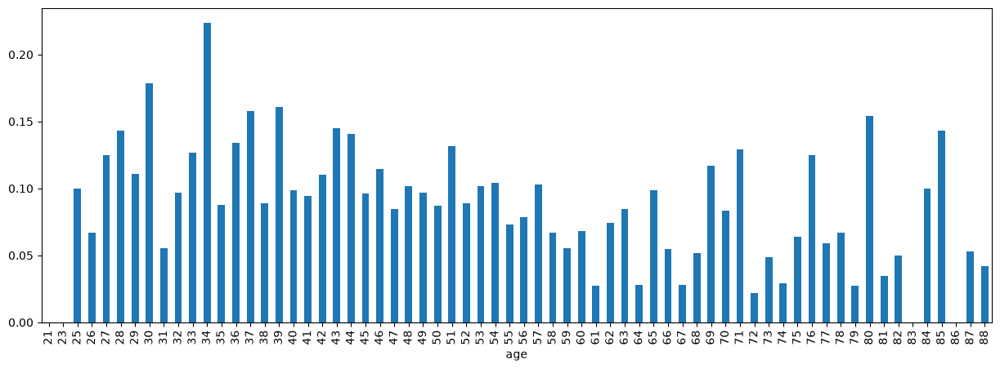

,count,sum,mean
gender,,,
0,2828,269,0.095120
1,2797,258,0.092242


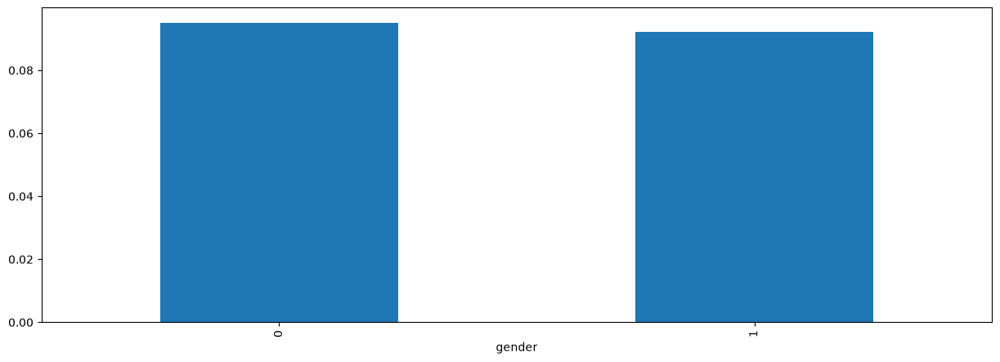

,count,sum,mean
city,,,
Екатеринбург,711,64,0.090014
Казань,727,55,0.075653
Москва,1570,146,0.092994
Нижний Новгород,693,68,0.098124
Новосибирск,970,103,0.106186
Санкт-Петербург,954,91,0.095388


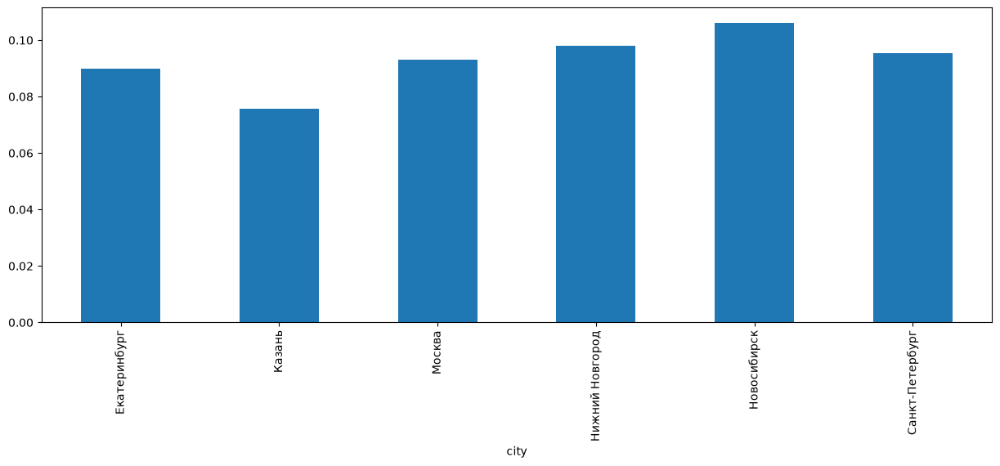

,count,sum,mean
segment,,,
Private,250,17,0.068000
Зарплатный,1524,59,0.038714
Массовый,2918,362,0.124058
Премиальный,933,89,0.095391


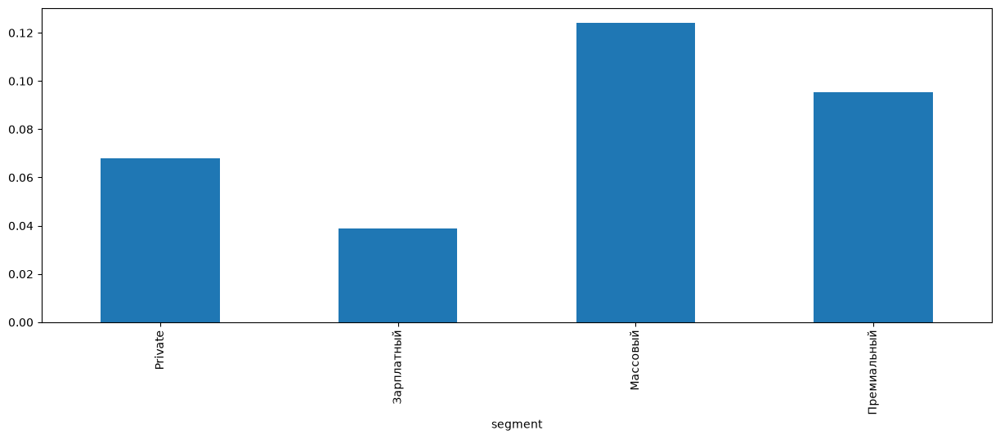

,count,sum,mean
loyalty_tier,,,
Базовый,2847,306,0.107482
Золото,964,81,0.084025
Платина,333,28,0.084084
Серебро,1481,112,0.075625


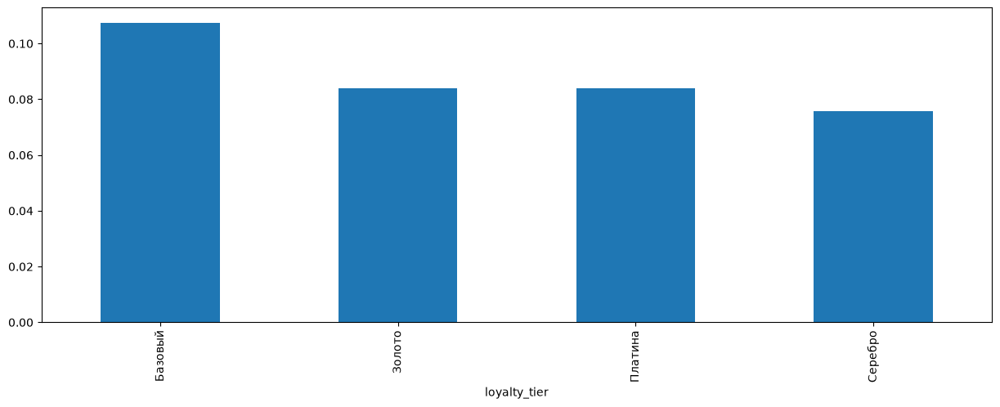

,count,sum,mean
card_type,,,
Дебетовая,3913,381,0.097368
Кредитная,1204,104,0.086379
Премиальная,508,42,0.082677


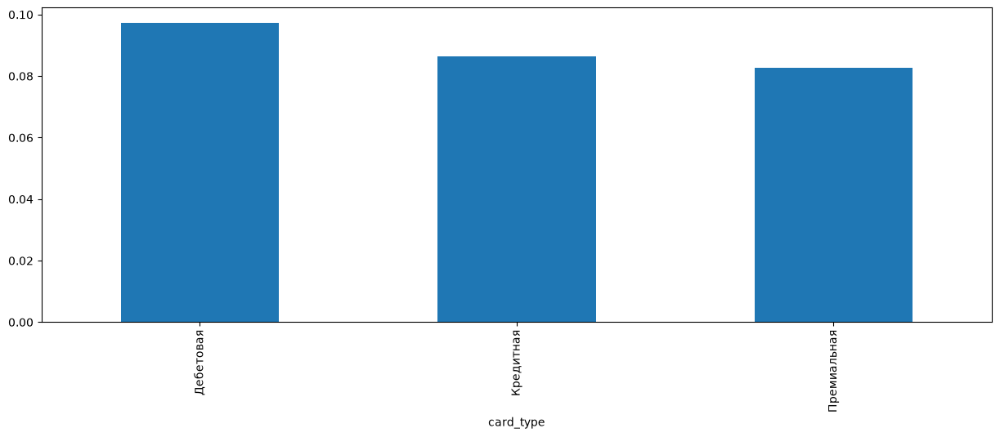

,count,sum,mean
registration_trunc_year,,,
2010-01-01,53,6,0.113208
2011-01-01,164,9,0.054878
2012-01-01,246,9,0.036585
2013-01-01,341,28,0.082111
2014-01-01,466,45,0.096567
2015-01-01,548,44,0.080292
2016-01-01,631,77,0.122029
2017-01-01,584,60,0.102740
2018-01-01,583,57,0.097770


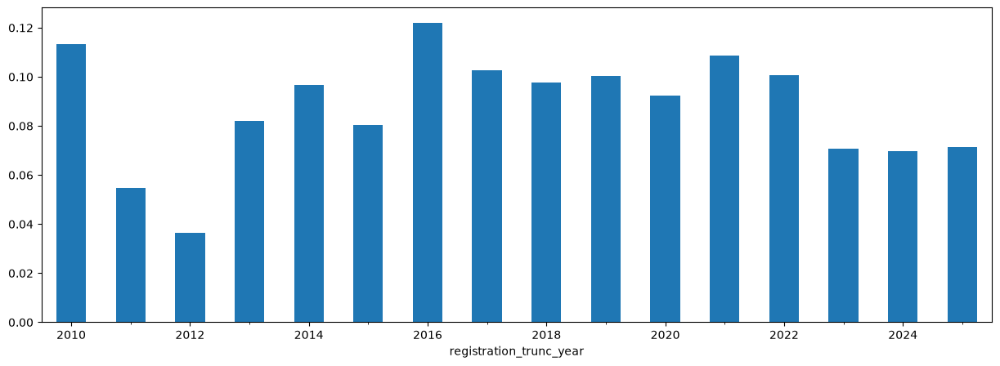

,count,sum,mean
card_open_date_trunc_year,,,
2016-01-01,616,37,0.060065
2017-01-01,624,55,0.088141
2018-01-01,589,61,0.103565
2019-01-01,592,48,0.081081
2020-01-01,580,52,0.089655
2021-01-01,606,76,0.125413
2022-01-01,602,65,0.107973
2023-01-01,567,56,0.098765
2024-01-01,472,54,0.114407


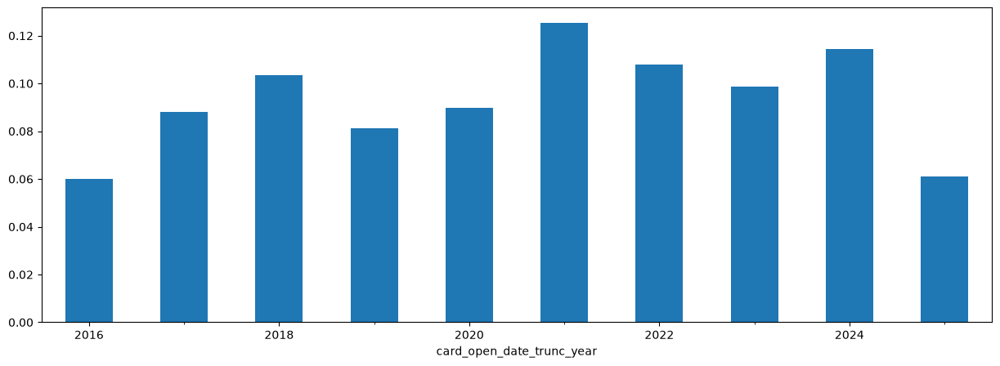

,count,sum,mean
income_source,,,
Зарплата в другом банке,1531,46,0.030046
Зарплата в нашем банке,2547,87,0.034158
Не указан,1547,394,0.254686


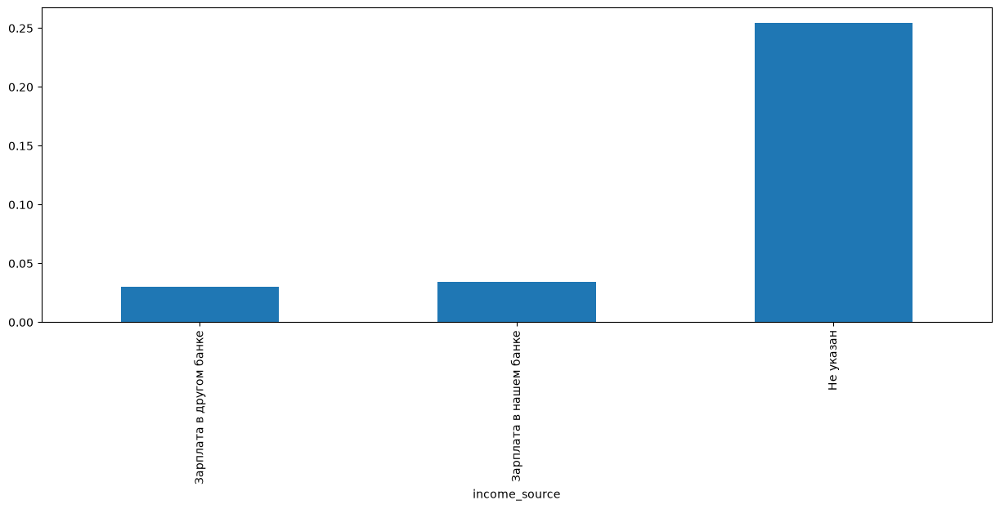

,count,sum,mean
has_mobile_app,,,
0,2135,194,0.090867
1,3490,333,0.095415


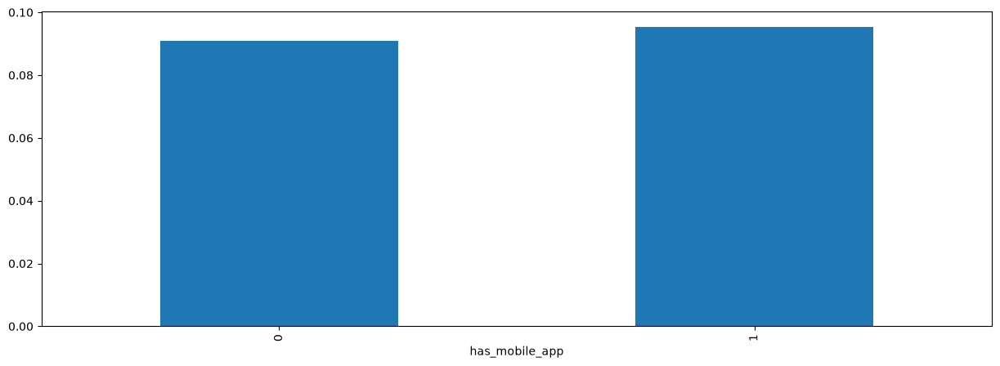

,count,sum,mean
satisfaction_score,,,
1.0,274,29,0.105839
2.0,448,32,0.071429
3.0,475,44,0.092632
4.0,450,44,0.097778
5.0,661,62,0.093797


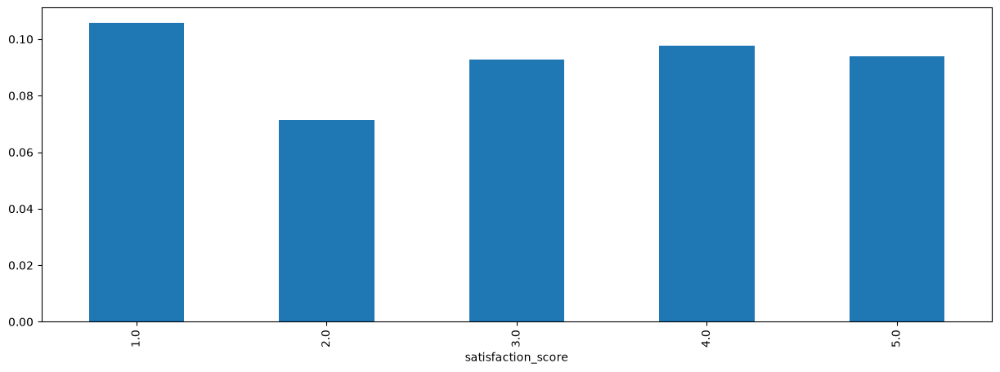

,count,sum,mean
marketing_opt_in,,,
0,663,64,0.096531
1,4962,463,0.093309


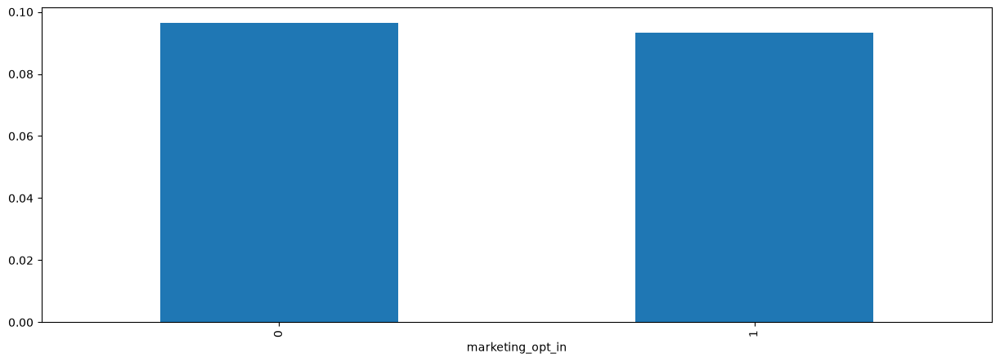

,count,sum,mean
app_last_login,,,
2024-01-01,156,13,0.083333
2024-02-01,163,13,0.079755
2024-03-01,217,19,0.087558
2024-04-01,193,11,0.056995
2024-05-01,191,15,0.078534
2024-06-01,197,20,0.101523
2024-07-01,203,21,0.103448
2024-08-01,203,18,0.088670
2024-09-01,206,20,0.097087


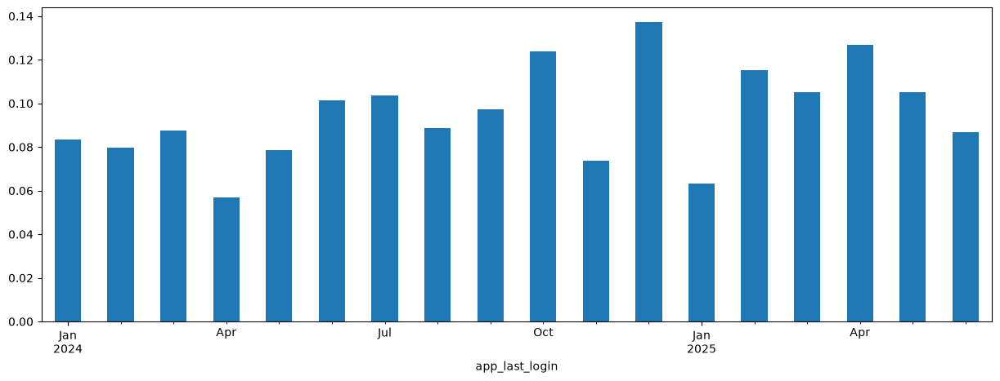

,count,sum,mean
app_last_login_isnull,,,
False,3490,333,0.095415
True,2135,194,0.090867


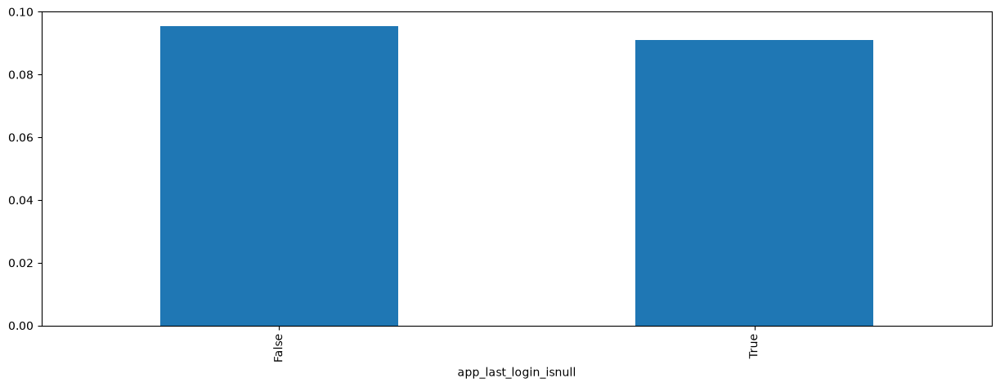

,count,sum,mean
satisfaction_score_isnull,,,
False,2308,211,0.091421
True,3317,316,0.095267


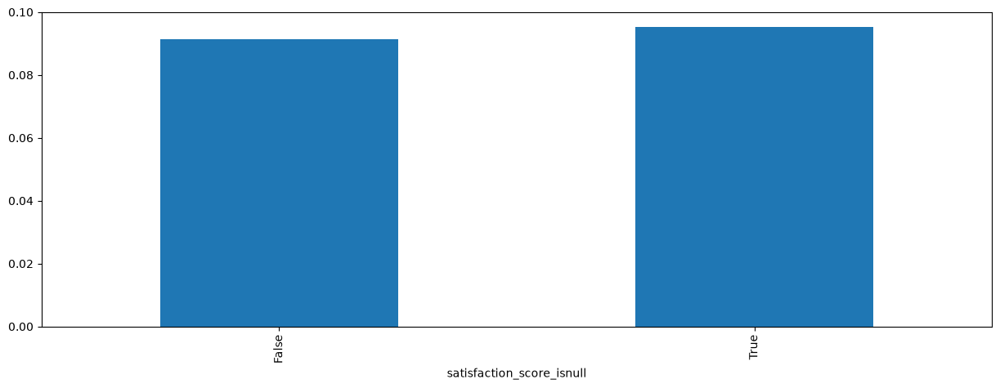

In [1031]:
for col in ['age', 'gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'registration_trunc_year', 
            'card_open_date_trunc_year', 'income_source', 'has_mobile_app', 'satisfaction_score', 
            'marketing_opt_in', 'app_last_login', 'app_last_login_isnull', 'satisfaction_score_isnull']:
    agg_miss_df = clients_df.groupby(col)['monthly_income_isnull'].agg(['count', 'sum', 'mean'])
    display(agg_miss_df)
    agg_miss_df['mean'].plot.bar(figsize=(15, 5))
    plt.show()


,count,mean,median
segment,,,
Private,233,350489.290558,338100.0
Зарплатный,1465,80691.343140,76500.0
Массовый,2556,63361.577621,59800.0
Премиальный,844,151564.702370,143050.0


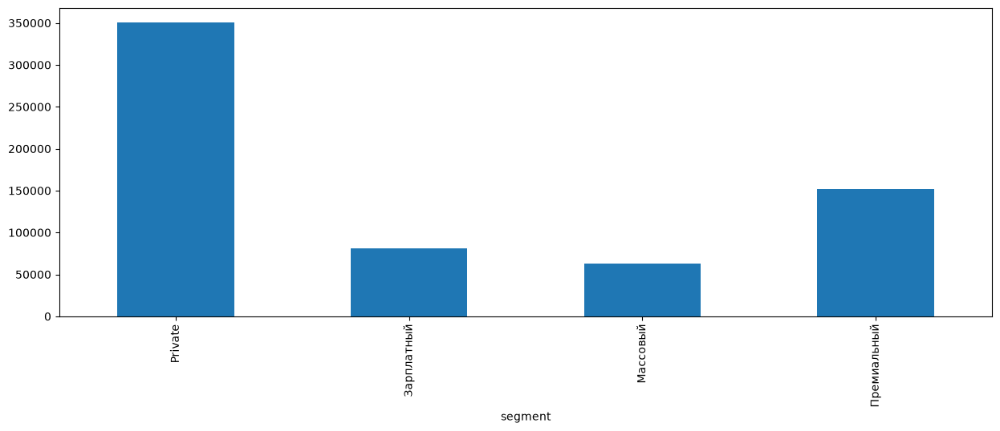

,count,mean,median
loyalty_tier,,,
Базовый,2541,69703.640024,63800.0
Золото,883,133481.659230,103600.0
Платина,305,221957.601639,176700.0
Серебро,1369,92820.526443,76900.0


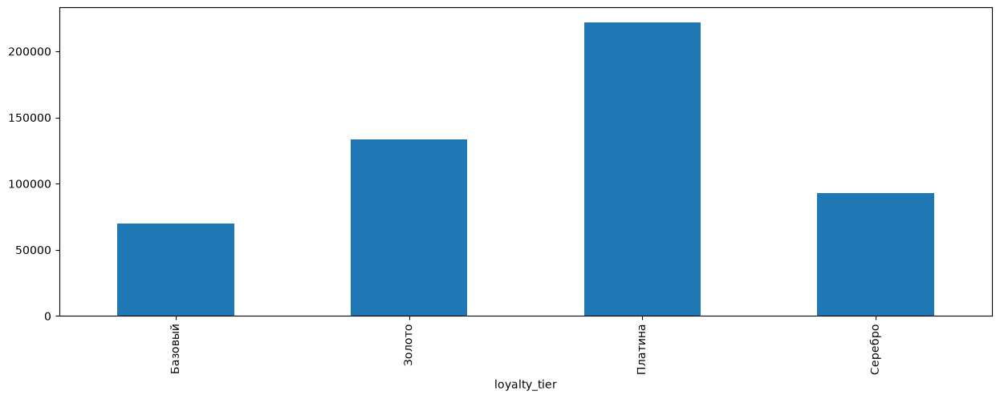

,count,mean,median
card_type,,,
Дебетовая,3532,81002.153964,68200.0
Кредитная,1100,95967.074818,76300.0
Премиальная,466,210485.479614,177300.0


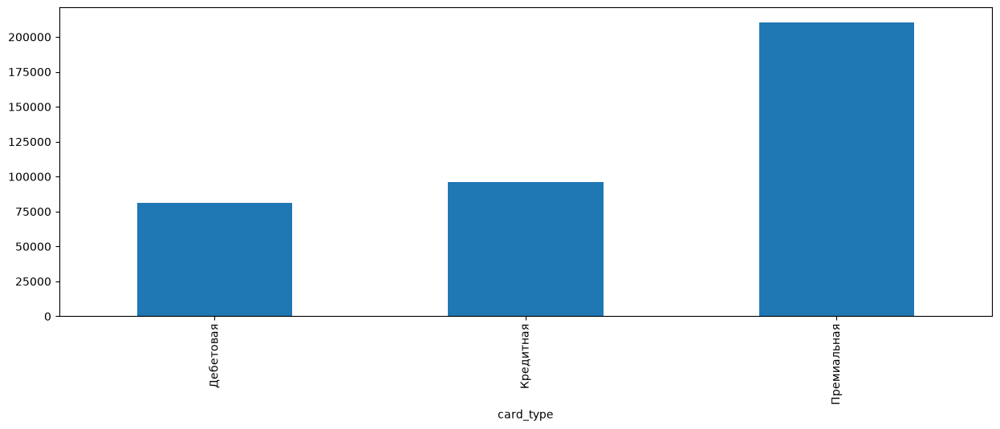

,count,mean,median
income_source,,,
Зарплата в другом банке,1485,103815.450370,71900.0
Зарплата в нашем банке,2460,93452.246179,77400.0
Не указан,1153,91666.222203,68100.0


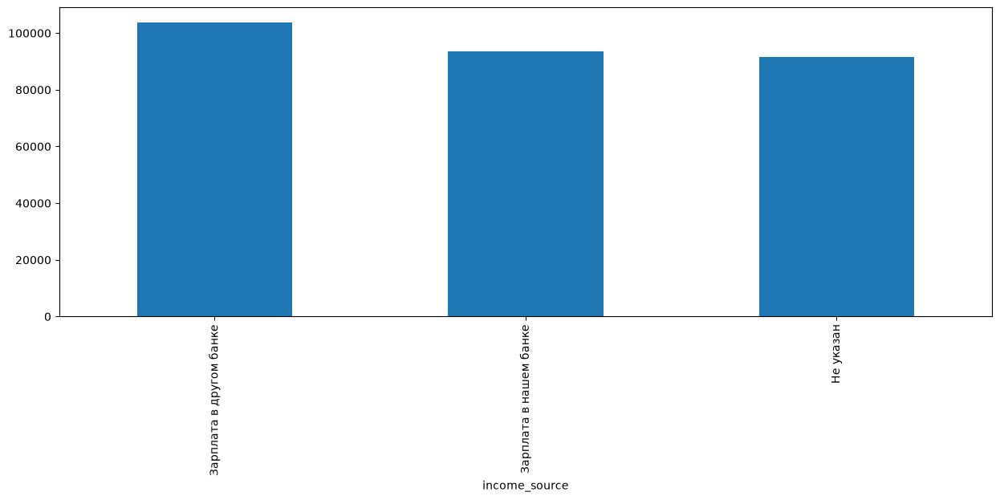

In [1032]:
for col in ['segment', 'loyalty_tier', 'card_type', 'income_source']:
    agg_miss_df = clients_df.groupby(col)['monthly_income'].agg(['count', 'mean', 'median'])
    display(agg_miss_df)
    agg_miss_df['mean'].plot.bar(figsize=(15, 5))
    plt.show()

In [1033]:
monthly_income_median_df = clients_df.groupby(['segment', 'loyalty_tier', 'card_type'])['monthly_income'].agg(['count', 'median'])
monthly_income_median_df

count    median
segment     loyalty_tier card_type                   
Private     Базовый      Дебетовая        2   82150.0
                         Премиальная      2  402000.0
            Золото       Дебетовая       14  320350.0
                         Кредитная        7  407000.0
                         Премиальная     61  334200.0
            Платина      Дебетовая       23  394400.0
                         Кредитная       18  303350.0
                         Премиальная     83  338100.0
            Серебро      Дебетовая        2  154528.6
                         Кредитная        6  297250.0
                         Премиальная     15  351400.0
Зарплатный  Базовый      Дебетовая      482   75150.0
                         Кредитная      163   76500.0
                         Премиальная     13   70400.0
            Золото       Дебетовая      182   76500.0
                         Кредитная       59   73500.0
                         Премиальная      6   80600.0
            Платина      Дебетовая       31   86400.0
                         Кредитная       14   75900.0
                         Премиальная      1  118200.0
            Серебро      Дебетовая      367   77800.0
                         Кредитная      140   76150.0
                         Премиальная      7   96300.0
Массовый    Базовый      Дебетовая     1471   59100.0
                         Кредитная      319   58700.0
                         Премиальная     15   62300.0
            Золото       Дебетовая      137   68700.0
                         Кредитная       38   70300.0
                         Премиальная      0       NaN
            Платина      Дебетовая       19   69500.0
                         Кредитная        5   46500.0
                         Премиальная      1   38500.0
            Серебро      Дебетовая      441   59700.0
                         Кредитная      106   60200.0
                         Премиальная      4   52750.0
Премиальный Базовый      Дебетовая       34  144550.0
                         Кредитная       20  130150.0
                         Премиальная     20  149200.0
            Золото       Дебетовая      169  150800.0
                         Кредитная       97  141100.0
                         Премиальная    113  143300.0
            Платина      Дебетовая       47  145600.0
                         Кредитная       34  158050.0
                         Премиальная     29  153100.0
            Серебро      Дебетовая      111  139300.0
                         Кредитная       74  149900.0
                         Премиальная     96  136750.0

Размер месячного дохода чаще всего не указывают клиенты, которые так же не указывают источник зарплаты. Чаще это пользователи из сегмента Массовый. Решено заполнить медианным доходом для сочетания `segment`, `loyalty_tier`, `card_type`

In [1034]:
for row in monthly_income_median_df.iterrows():
    segment, loyalty_tier, card_type = row[0]
    median = row[1]['median']
    if segment == 'Массовый' and loyalty_tier == 'Золото' and card_type == 'Премиальная':
        median = 70000.0
    clients_df.loc[(clients_df['segment'] == segment) & (clients_df['loyalty_tier'] == loyalty_tier) & (clients_df['card_type'] == card_type) & (clients_df['monthly_income'].isnull()), 'monthly_income'] = median

,count,sum,mean
age,,,
21,1,0,0.000000
23,1,0,0.000000
25,10,0,0.000000
26,15,1,0.066667
27,16,0,0.000000
...,...,...,...
84,20,13,0.650000
85,21,18,0.857143
86,21,17,0.809524


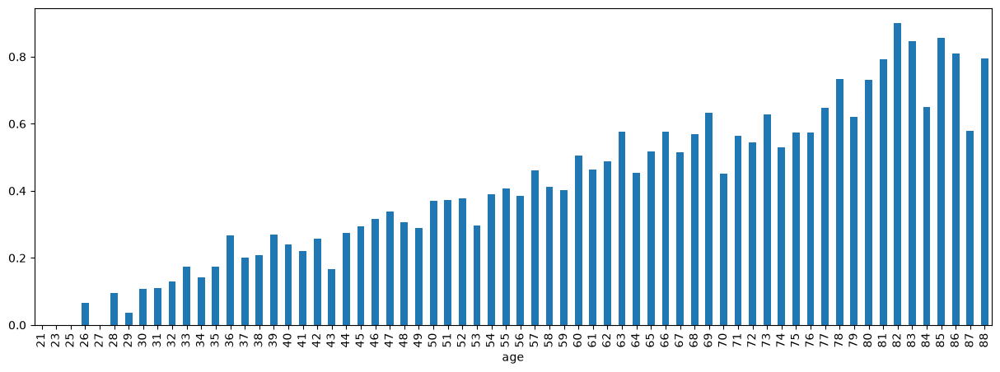

,count,sum,mean
gender,,,
0,2828,1052,0.371994
1,2797,1083,0.387201


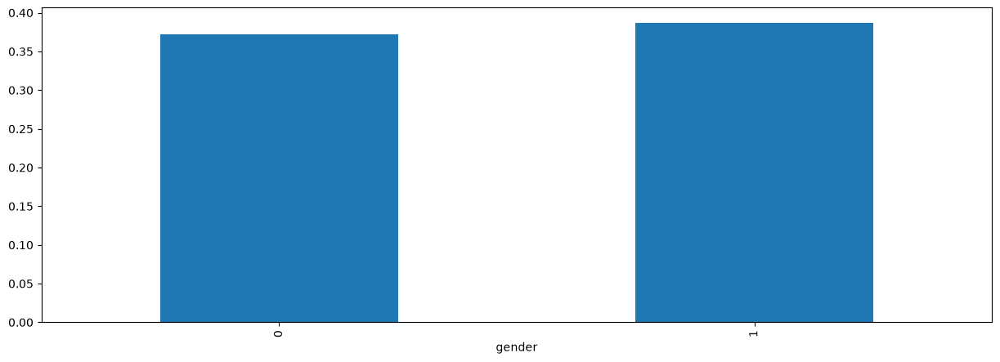

,count,sum,mean
city,,,
Екатеринбург,711,248,0.348805
Казань,727,283,0.389271
Москва,1570,607,0.386624
Нижний Новгород,693,251,0.362193
Новосибирск,970,364,0.375258
Санкт-Петербург,954,382,0.400419


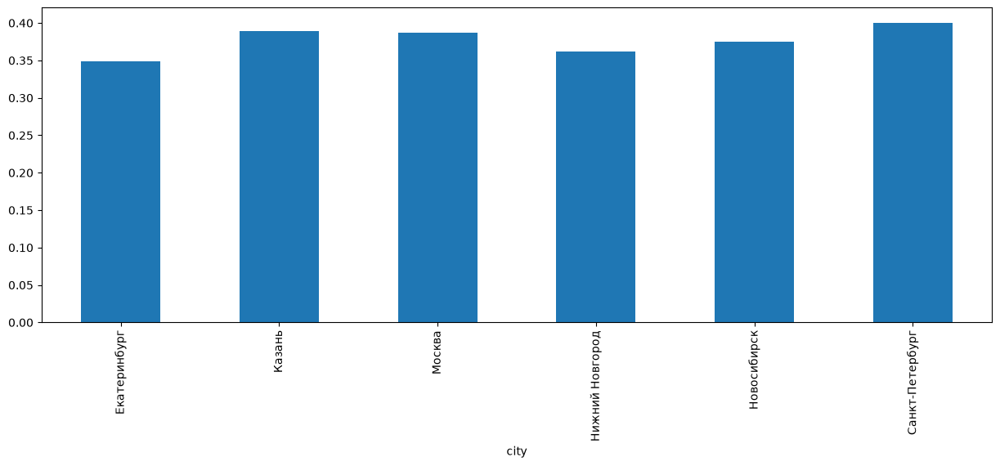

,count,sum,mean
segment,,,
Private,250,99,0.396000
Зарплатный,1524,574,0.376640
Массовый,2918,1113,0.381426
Премиальный,933,349,0.374062


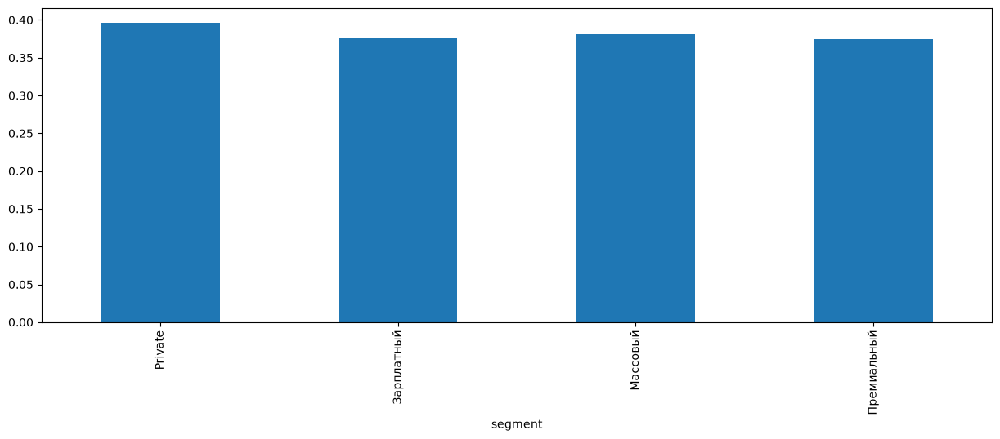

,count,sum,mean
loyalty_tier,,,
Базовый,2847,1085,0.381103
Золото,964,365,0.378631
Платина,333,131,0.393393
Серебро,1481,554,0.374072


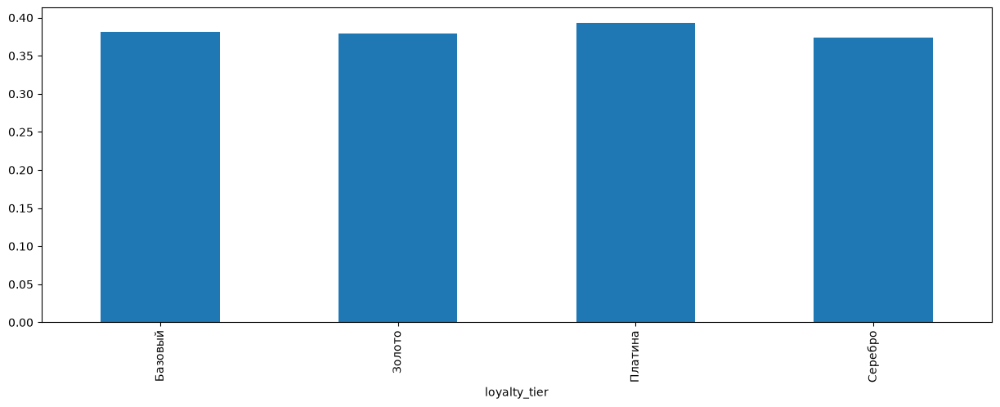

,count,sum,mean
card_type,,,
Дебетовая,3913,1501,0.383593
Кредитная,1204,443,0.367940
Премиальная,508,191,0.375984


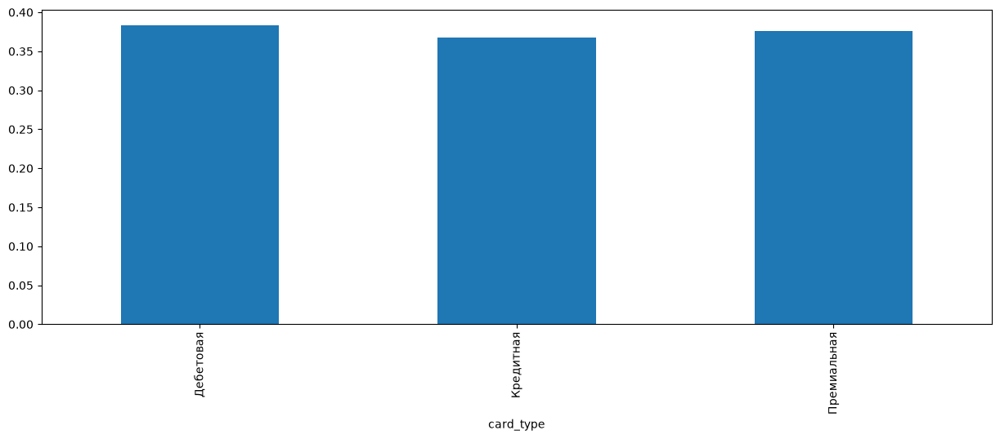

,count,sum,mean
registration_trunc_year,,,
2010-01-01,53,24,0.452830
2011-01-01,164,70,0.426829
2012-01-01,246,101,0.410569
2013-01-01,341,131,0.384164
2014-01-01,466,171,0.366953
2015-01-01,548,218,0.397810
2016-01-01,631,250,0.396197
2017-01-01,584,231,0.395548
2018-01-01,583,226,0.387650


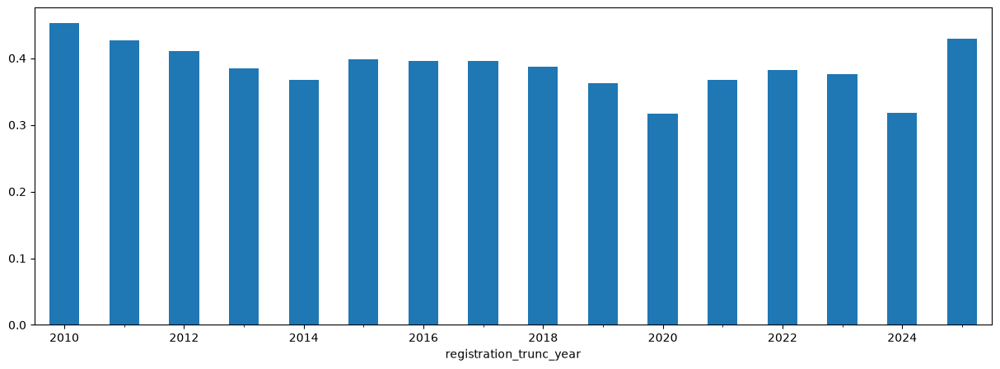

,count,sum,mean
card_open_date_trunc_year,,,
2016-01-01,616,252,0.409091
2017-01-01,624,235,0.376603
2018-01-01,589,245,0.415959
2019-01-01,592,206,0.347973
2020-01-01,580,232,0.400000
2021-01-01,606,236,0.389439
2022-01-01,602,222,0.368771
2023-01-01,567,213,0.375661
2024-01-01,472,168,0.355932


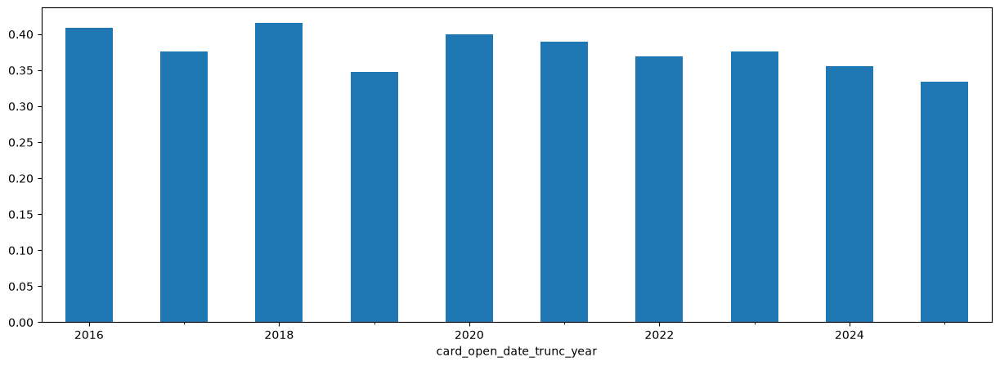

,count,sum,mean
income_source,,,
Зарплата в другом банке,1531,570,0.372306
Зарплата в нашем банке,2547,951,0.373380
Не указан,1547,614,0.396897


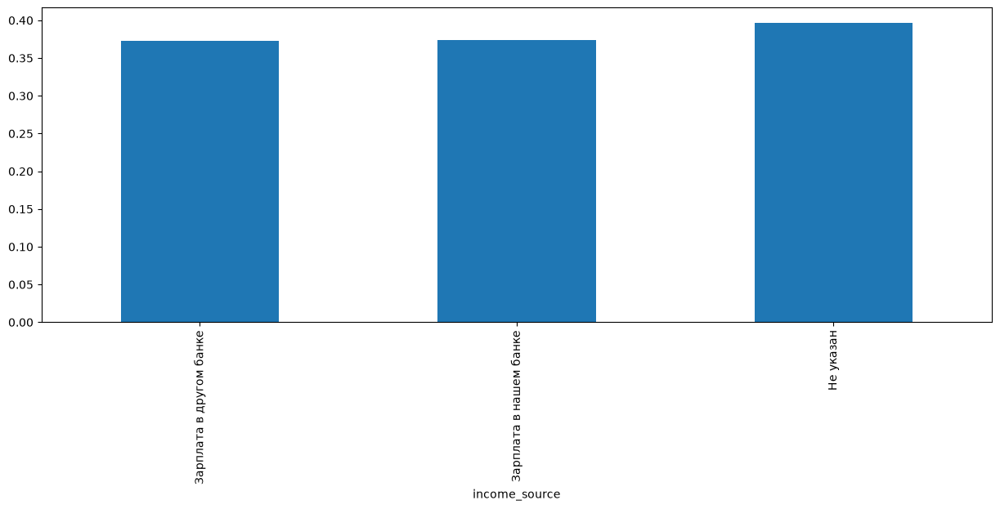

,count,sum,mean
has_mobile_app,,,
0,2135,2135,1.0
1,3490,0,0.0


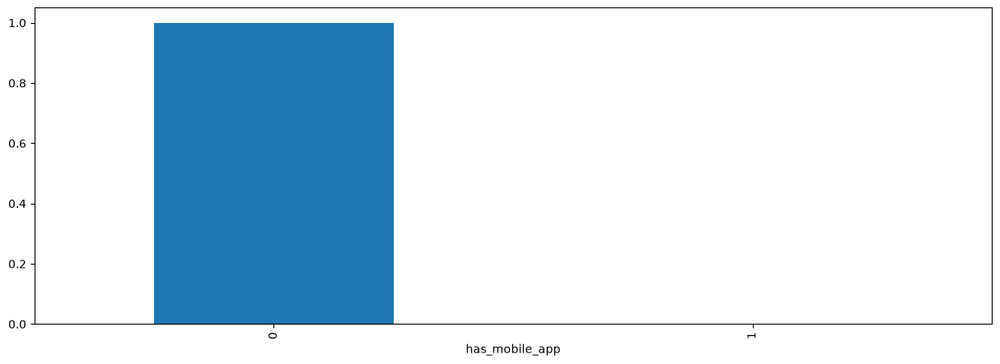

,count,sum,mean
satisfaction_score,,,
1.0,274,118,0.430657
2.0,448,172,0.383929
3.0,475,193,0.406316
4.0,450,162,0.360000
5.0,661,230,0.347958


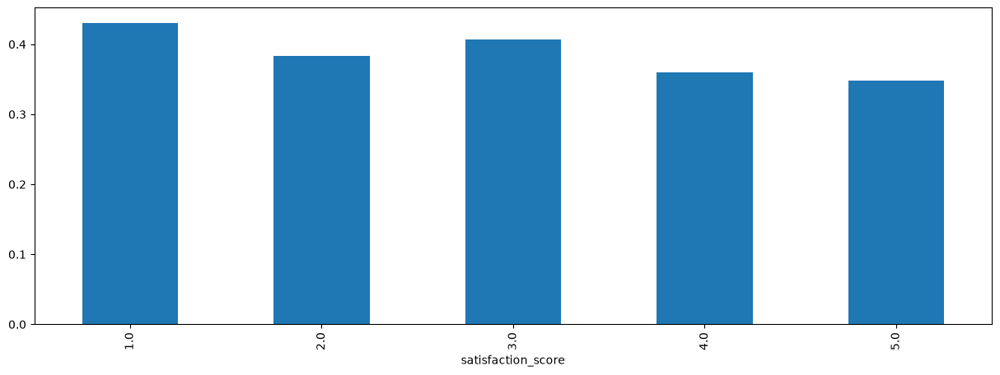

,count,sum,mean
marketing_opt_in,,,
0,663,248,0.374057
1,4962,1887,0.380290


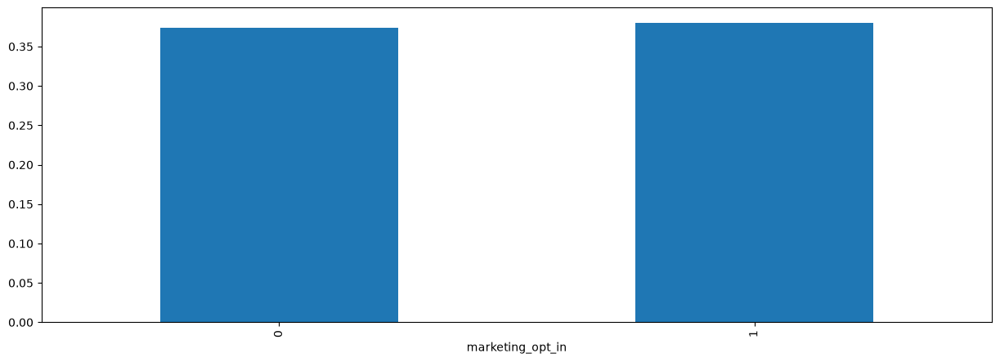

,count,sum,mean
satisfaction_score_isnull,,,
False,2308,875,0.379116
True,3317,1260,0.379861


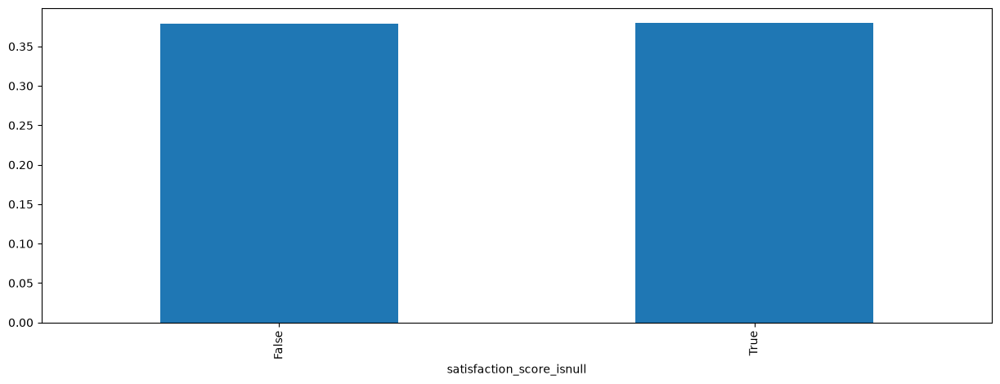

In [1035]:
for col in ['age', 'gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'registration_trunc_year', 
            'card_open_date_trunc_year', 'income_source', 'has_mobile_app', 'satisfaction_score', 
            'marketing_opt_in', 'satisfaction_score_isnull']:
    agg_miss_df = clients_df.groupby(col)['app_last_login_isnull'].agg(['count', 'sum', 'mean'])
    display(agg_miss_df)
    agg_miss_df['mean'].plot.bar(figsize=(15, 5))
    plt.show()

С возрастом клиента растет процент пропусков в дате последнего захода в приложение. Все пропуски там, где `has_mobile_app` равно 0 (то есть приложение отсутствует). Из этого можно сделать вывод, что поле `app_last_login` имеет пропуски только если у клиента нет приложения. Чем больше возраст клиентов, тем меньше среди них юзеров приложения. Этот пропуск оставляем как есть.

,count,sum,mean
age,,,
21,1,0,0.000000
23,1,1,1.000000
25,10,4,0.400000
26,15,11,0.733333
27,16,12,0.750000
...,...,...,...
84,20,11,0.550000
85,21,13,0.619048
86,21,11,0.523810


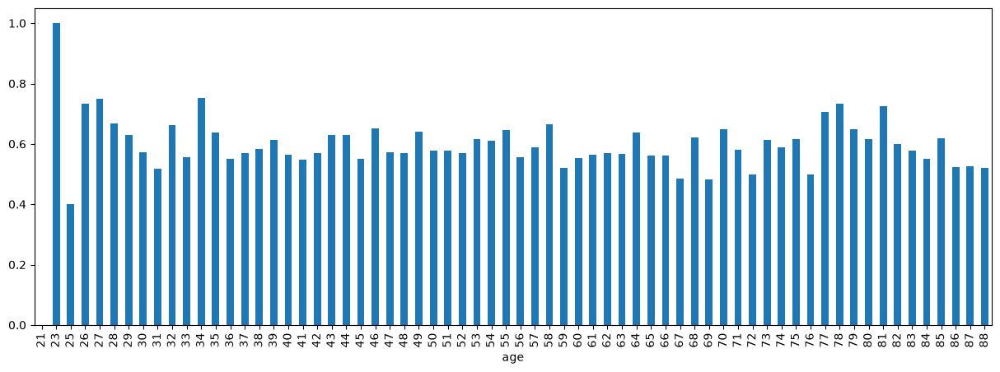

,count,sum,mean
gender,,,
0,2828,1678,0.593352
1,2797,1639,0.585985


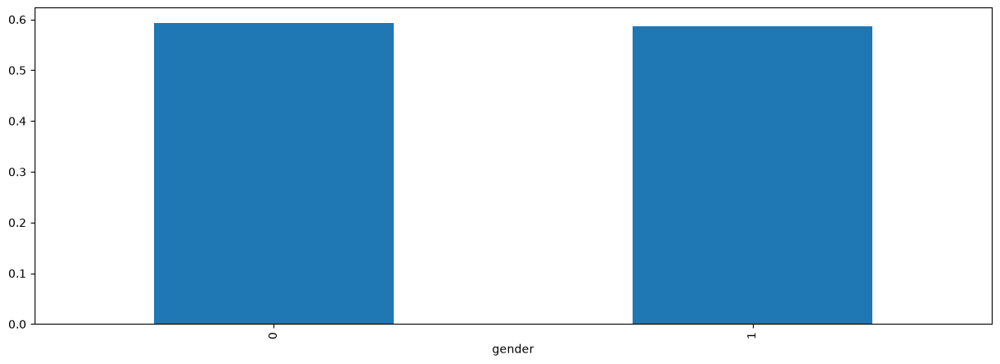

,count,sum,mean
city,,,
Екатеринбург,711,388,0.545710
Казань,727,432,0.594223
Москва,1570,896,0.570701
Нижний Новгород,693,414,0.597403
Новосибирск,970,643,0.662887
Санкт-Петербург,954,544,0.570231


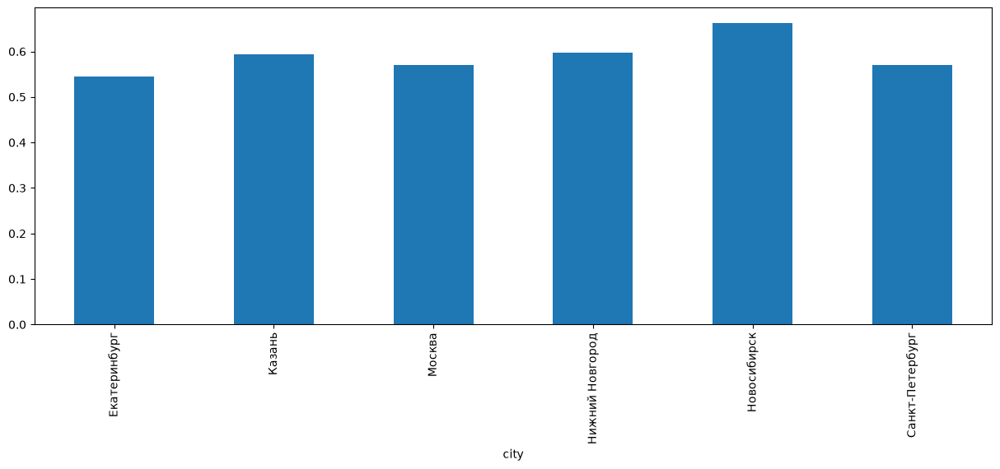

,count,sum,mean
segment,,,
Private,250,96,0.384000
Зарплатный,1524,919,0.603018
Массовый,2918,1908,0.653873
Премиальный,933,394,0.422294


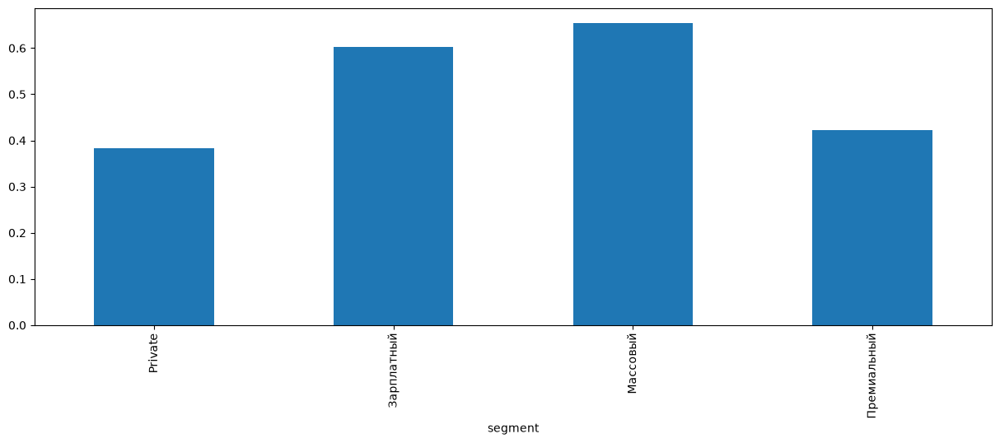

,count,sum,mean
loyalty_tier,,,
Базовый,2847,1914,0.672287
Золото,964,274,0.284232
Платина,333,86,0.258258
Серебро,1481,1043,0.704254


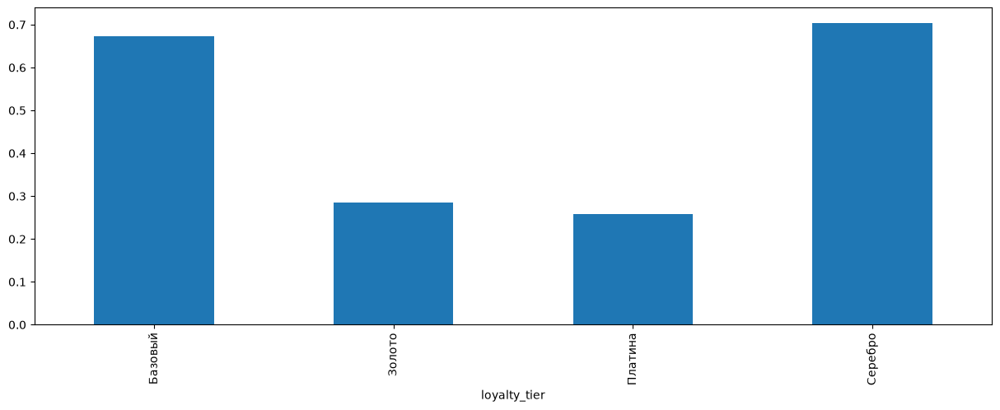

,count,sum,mean
card_type,,,
Дебетовая,3913,2400,0.613340
Кредитная,1204,693,0.575581
Премиальная,508,224,0.440945


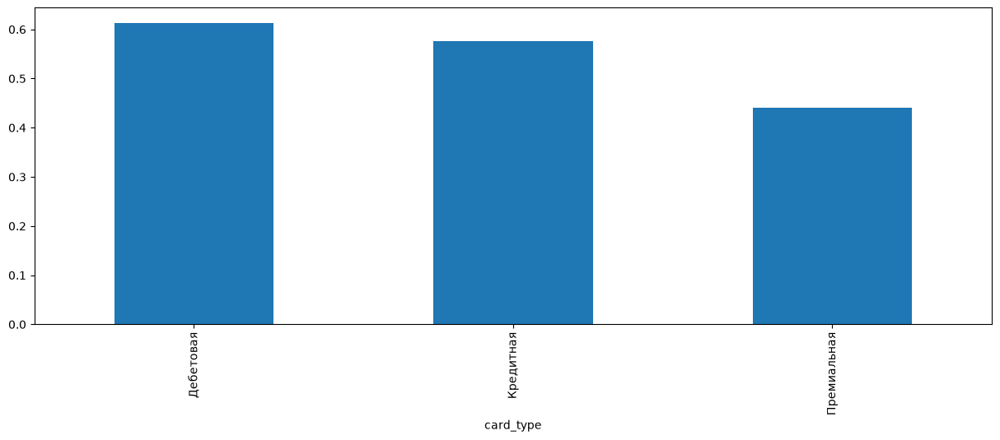

,count,sum,mean
registration_trunc_year,,,
2010-01-01,53,33,0.622642
2011-01-01,164,89,0.542683
2012-01-01,246,149,0.605691
2013-01-01,341,207,0.607038
2014-01-01,466,288,0.618026
2015-01-01,548,321,0.585766
2016-01-01,631,383,0.606973
2017-01-01,584,343,0.587329
2018-01-01,583,354,0.607204


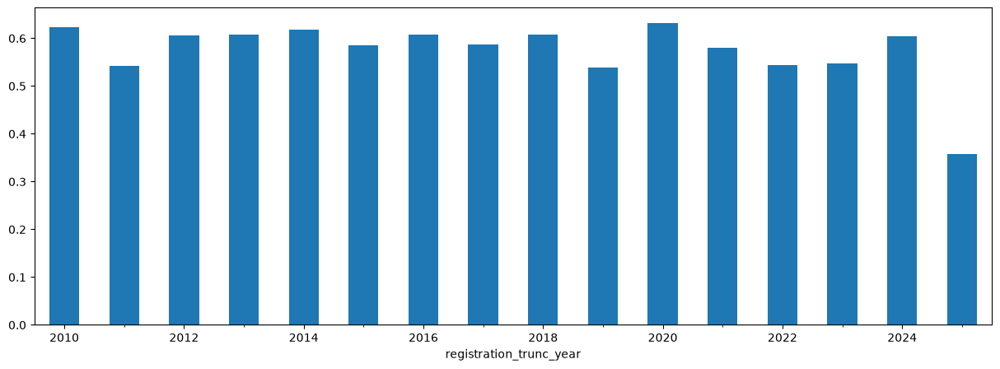

,count,sum,mean
card_open_date_trunc_year,,,
2016-01-01,616,378,0.613636
2017-01-01,624,374,0.599359
2018-01-01,589,356,0.604414
2019-01-01,592,339,0.572635
2020-01-01,580,340,0.586207
2021-01-01,606,347,0.572607
2022-01-01,602,366,0.607973
2023-01-01,567,326,0.574956
2024-01-01,472,264,0.559322


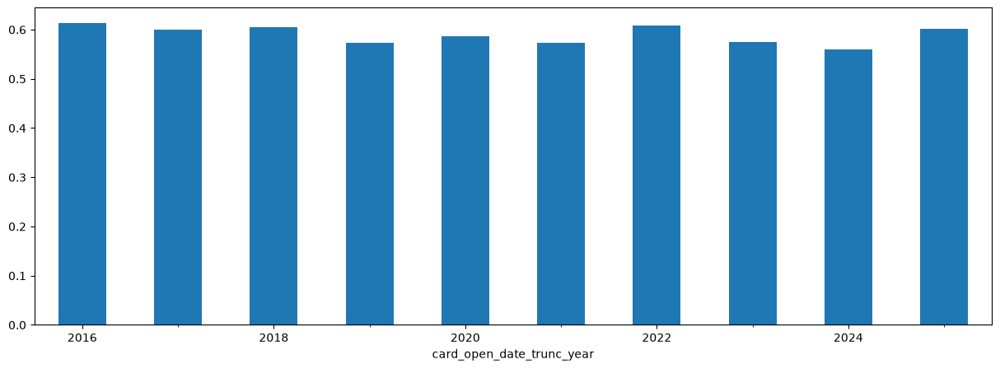

,count,sum,mean
income_source,,,
Зарплата в другом банке,1531,877,0.572828
Зарплата в нашем банке,2547,1490,0.585002
Не указан,1547,950,0.614092


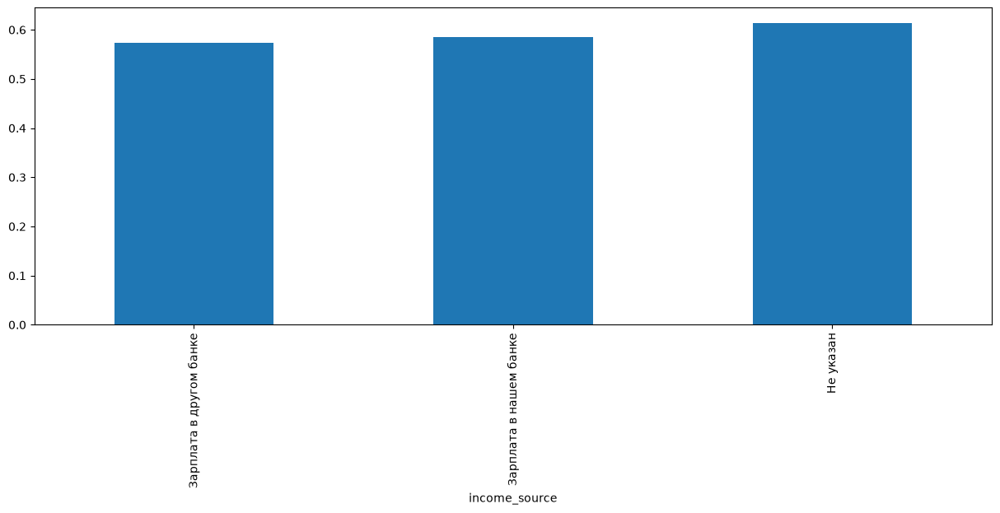

,count,sum,mean
has_mobile_app,,,
0,2135,1260,0.590164
1,3490,2057,0.589398


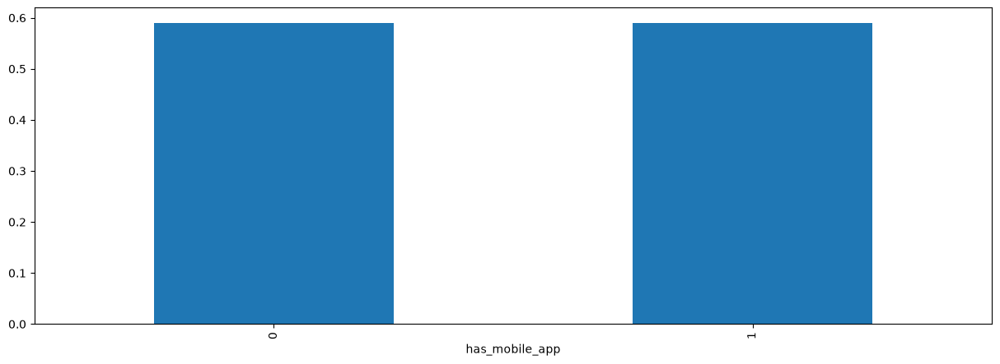

,count,sum,mean
marketing_opt_in,,,
0,663,391,0.589744
1,4962,2926,0.589682


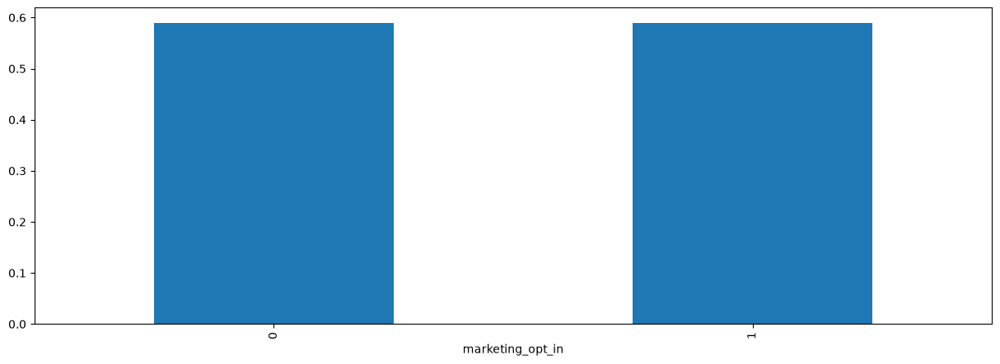

,count,sum,mean
app_last_login,,,
2024-01-01,156,88,0.564103
2024-02-01,163,97,0.595092
2024-03-01,217,130,0.599078
2024-04-01,193,102,0.528497
2024-05-01,191,113,0.591623
2024-06-01,197,118,0.598985
2024-07-01,203,115,0.566502
2024-08-01,203,118,0.581281
2024-09-01,206,117,0.567961


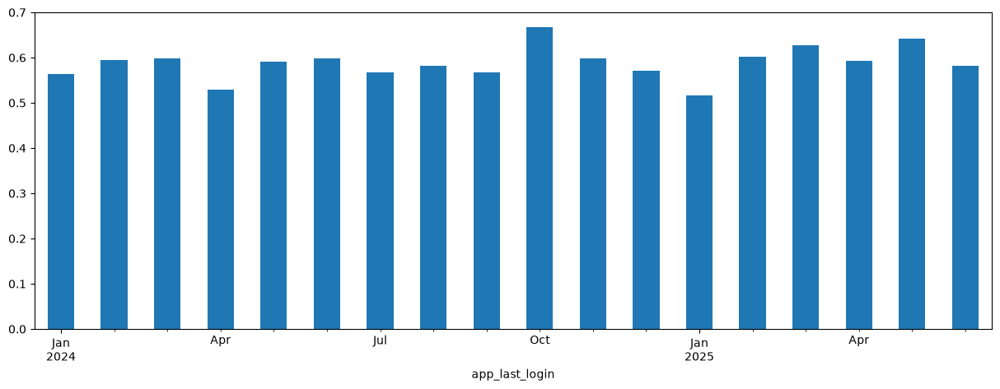

,count,sum,mean
app_last_login_isnull,,,
False,3490,2057,0.589398
True,2135,1260,0.590164


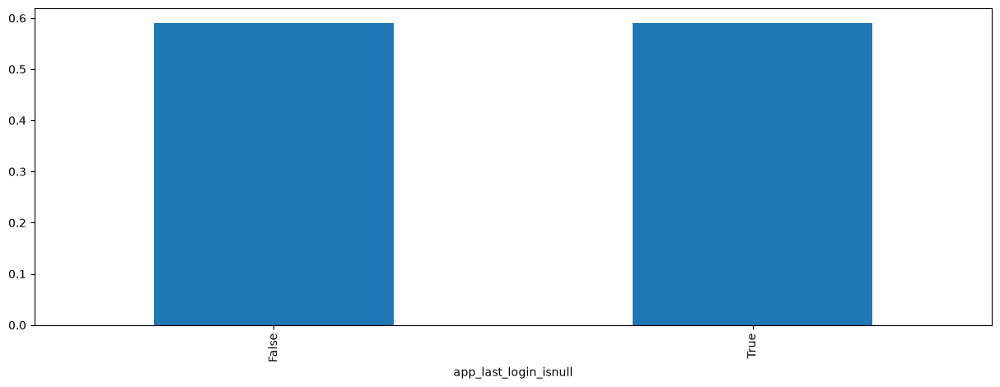

In [1036]:
for col in ['age', 'gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'registration_trunc_year', 
            'card_open_date_trunc_year', 'income_source', 'has_mobile_app', 
            'marketing_opt_in', 'app_last_login', 'app_last_login_isnull']:
    agg_miss_df = clients_df.groupby(col)['satisfaction_score_isnull'].agg(['count', 'sum', 'mean'])
    display(agg_miss_df)
    agg_miss_df['mean'].plot.bar(figsize=(15, 5))
    plt.show()

Оценку чаще не ставят пользователи из сегментов Зарплатный и Массовый. А также с `loyalty_tier` из Базовый и Серебро. С `card_type` Кредитная и Дебетовая. На анализ это не должно влиять. Заполним пропуски заглушкой 0.

In [1037]:
clients_df['satisfaction_score'] = clients_df['satisfaction_score'].fillna(0)

In [1038]:
clients_df.info()

<class 'pandas.DataFrame'>
Index: 5625 entries, 0 to 5665
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   client_id                  5625 non-null   str           
 1   birth_date                 5625 non-null   datetime64[us]
 2   gender                     5625 non-null   int64         
 3   city                       5625 non-null   str           
 4   segment                    5625 non-null   str           
 5   loyalty_tier               5625 non-null   str           
 6   card_type                  5625 non-null   str           
 7   registration_date          5625 non-null   datetime64[us]
 8   card_open_date             5625 non-null   datetime64[us]
 9   income_source              5625 non-null   str           
 10  monthly_income             5625 non-null   float64       
 11  has_mobile_app             5625 non-null   int64         
 12  app_last_login        

### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [1039]:
clients_df.describe()

,birth_date,gender,registration_date,card_open_date,monthly_income,has_mobile_app,app_last_login,satisfaction_score,marketing_opt_in,age,registration_trunc_year,card_open_date_trunc_year
count,5625,5625.000000,5625,5625,5625.000000,5625.000000,3490,5625.000000,5625.000000,5625.000000,5625,5625
mean,1971-11-24 15:42:35.520000,0.497244,2017-09-06 11:23:31.200000,2020-09-14 10:43:50.400000,95054.537529,0.620444,2024-09-19 01:32:00.687679,1.368889,0.882133,53.131200,2017-03-10 04:25:59.040000,2020-03-17 20:42:52.800000
min,1936-07-23 00:00:00,0.000000,2010-01-08 00:00:00,2016-01-01 00:00:00,-999.000000,0.000000,2024-01-01 00:00:00,0.000000,0.000000,21.000000,2010-01-01 00:00:00,2016-01-01 00:00:00
25%,1963-01-14 00:00:00,0.000000,2015-04-02 00:00:00,2018-04-08 00:00:00,54700.000000,0.000000,2024-05-01 00:00:00,0.000000,1.000000,43.000000,2015-01-01 00:00:00,2018-01-01 00:00:00
50%,1973-10-25 00:00:00,0.000000,2017-08-04 00:00:00,2020-08-30 00:00:00,71600.000000,1.000000,2024-10-01 00:00:00,0.000000,1.000000,51.000000,2017-01-01 00:00:00,2020-01-01 00:00:00
75%,1982-07-08 00:00:00,1.000000,2020-01-29 00:00:00,2023-01-06 00:00:00,107700.000000,1.000000,2025-02-01 00:00:00,3.000000,1.000000,62.000000,2020-01-01 00:00:00,2023-01-01 00:00:00
max,2003-08-28 00:00:00,1.000000,2025-04-27 00:00:00,2025-05-16 00:00:00,865400.000000,1.000000,2025-06-01 00:00:00,5.000000,1.000000,88.000000,2025-01-01 00:00:00,2025-01-01 00:00:00
std,NaN,0.500037,NaN,NaN,79737.970402,0.485319,NaN,1.863284,0.322479,14.128054,NaN,NaN


<Axes: ylabel='Frequency'>

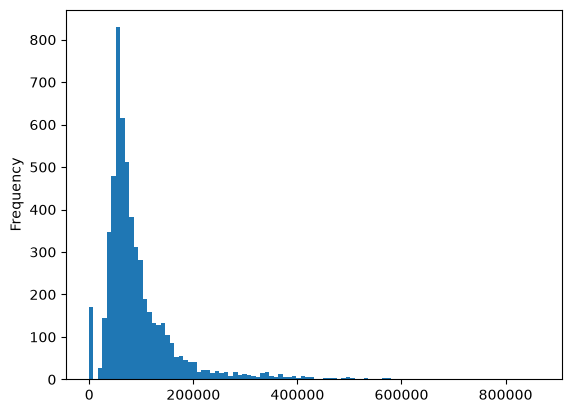

In [1040]:
clients_df['monthly_income'].plot.hist(bins=100)

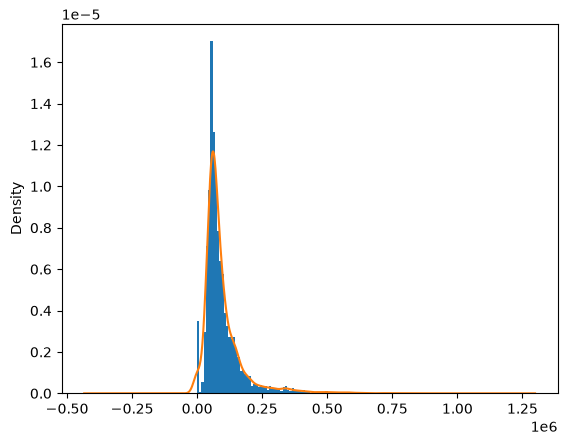

In [1041]:
clients_df['monthly_income'].plot.hist(bins=100, density=True)
clients_df['monthly_income'].plot.density()
plt.show()

Виден пик у нуля и около 100_000

<Axes: ylabel='Frequency'>

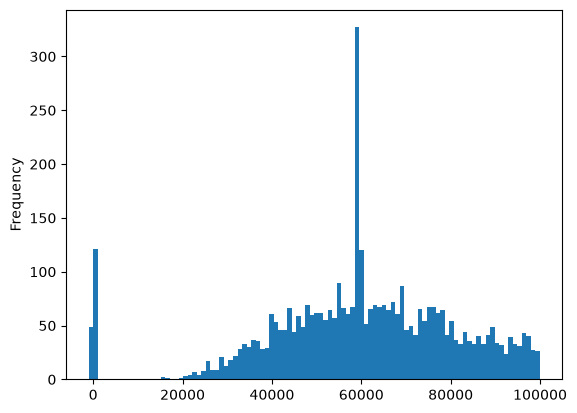

In [1042]:
clients_df.loc[clients_df['monthly_income'] < 100_000, 'monthly_income'].plot.hist(bins=100)

In [1043]:
clients_df['monthly_income'].mode()

0    59100.0
Name: monthly_income, dtype: float64

Необычный пик на 59100.0 - значение, которым заполнялись пропуски в Массовом сегменте, Базовым уровнем лояльности и Дебетовой картой.

In [1044]:
clients_df.loc[clients_df['monthly_income'] == 59100.0].groupby(['segment', 'loyalty_tier', 'card_type'])['monthly_income'].count()

segment     loyalty_tier  card_type
Зарплатный  Базовый       Дебетовая      1
            Серебро       Дебетовая      2
Массовый    Базовый       Дебетовая    215
                          Кредитная      1
            Серебро       Дебетовая      1
                          Кредитная      1
Name: monthly_income, dtype: int64

<Axes: ylabel='Frequency'>

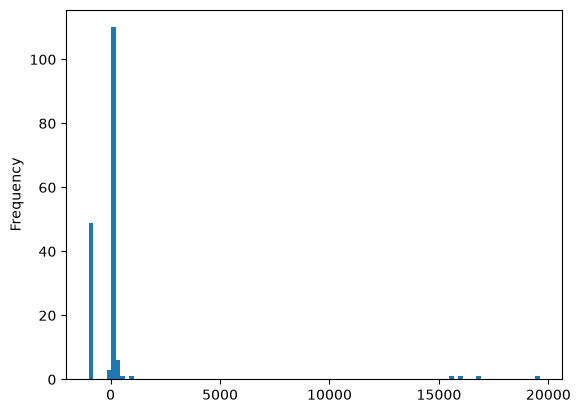

In [1045]:
clients_df.loc[clients_df['monthly_income'] < 20_000, 'monthly_income'].plot.hist(bins=100)

In [1046]:
under_1000 = sum(clients_df['monthly_income'] < 15000)
clients_cnt = clients_df['monthly_income'].shape[0]
under_1000_pct = under_1000 / clients_cnt
print(f'Количество клиентов с доходом ниже 15_000: {under_1000} ({under_1000_pct:.2%})')

Количество клиентов с доходом ниже 15_000: 170 (3.02%)


Такой доход можно считать ошибкой (особенно отрицательный), заменим на медиану, как при пропуске. Так же пометим в поле `monthly_income_isnull` как пропуск.

In [1047]:
clients_df.loc[clients_df['monthly_income'] < 15000, 'monthly_income_isnull'] = True
for row in monthly_income_median_df.iterrows():
    segment, loyalty_tier, card_type = row[0]
    median = row[1]['median']
    if segment == 'Массовый' and loyalty_tier == 'Золото' and card_type == 'Премиальная':
        median = 70000.0
    clients_df.loc[(clients_df['segment'] == segment) & (clients_df['loyalty_tier'] == loyalty_tier) & (clients_df['card_type'] == card_type) & (clients_df['monthly_income'] < 15000), 'monthly_income'] = median

In [1048]:
fig = px.box(clients_df, x='segment', y='monthly_income')
fig.show()

In [1049]:
fig = px.box(clients_df, x='loyalty_tier', y='monthly_income')
fig.show()

In [1050]:
fig = px.box(clients_df, x='card_type', y='monthly_income')
fig.show()

Выбросы по правую сторону можно расматривать как реальный доход. Исправлять не будем.

#### txns_df

In [1051]:
txns_df.info()

<class 'pandas.DataFrame'>
Index: 616922 entries, 5 to 241812
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        616922 non-null  int64         
 1   client_id     616922 non-null  str           
 2   txn_datetime  616922 non-null  datetime64[us]
 3   amount        616922 non-null  float64       
 4   currency      616922 non-null  str           
 5   category      616922 non-null  str           
 6   mcc_code      616922 non-null  int64         
 7   channel       616922 non-null  str           
 8   status        616922 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(5)
memory usage: 47.1 MB


In [1052]:
txns_df.describe()

,txn_id,txn_datetime,amount,mcc_code
count,616922.000000,616922,616922.000000,616922.000000
mean,408927.189066,2024-09-24 14:20:29.054150,1873.371961,5591.184686
min,100001.000000,2023-12-03 07:08:38,-38125.210000,4111.000000
25%,254231.250000,2024-05-19 10:34:08.500000,469.360000,5411.000000
50%,408461.500000,2024-09-21 16:55:33,1070.760000,5541.000000
75%,562691.750000,2025-01-26 13:09:50.750000,2262.757500,5812.000000
max,990220.000000,2026-08-01 00:00:00,143791.170000,7832.000000
std,178905.397919,NaN,2724.408913,859.648426


In [1053]:
txns_df['currency'].value_counts()

currency
RUB    614457
EUR      1258
USD      1207
Name: count, dtype: int64

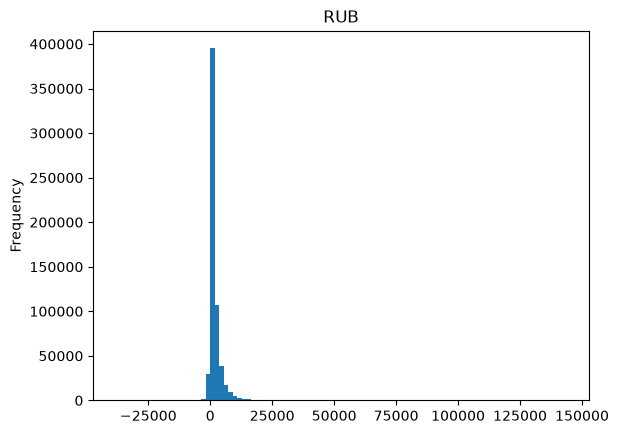

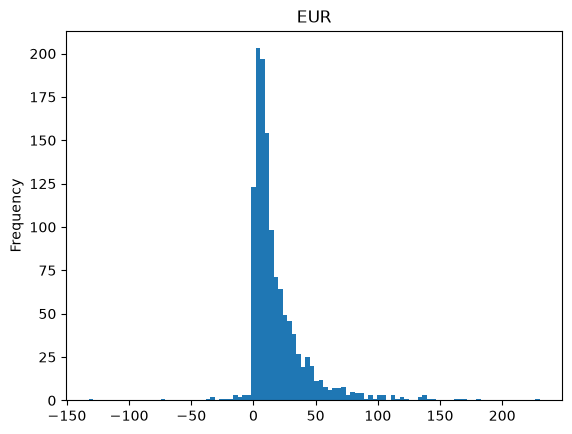

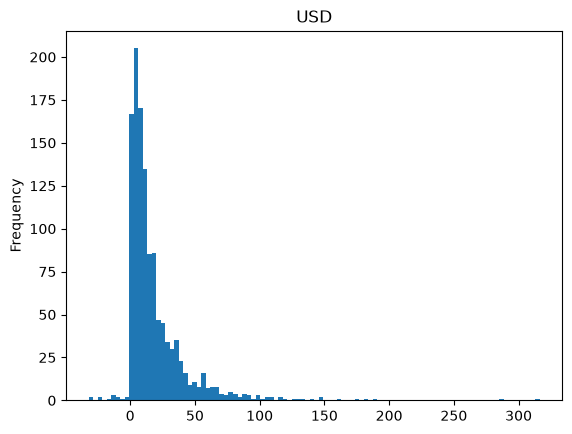

In [1054]:
for currency in txns_df['currency'].unique():
    txns_df.loc[txns_df['currency'] == currency, 'amount'].plot.hist(bins=100, title=currency)
    plt.show()


In [1055]:
print('Количество отрицательных значений в поле amount', sum(txns_df['amount'] < 0))

Количество отрицательных значений в поле amount 7347


Судя по данным, отрицательные значения `amount` не являются правильными. Возбмем модуль из данного поля

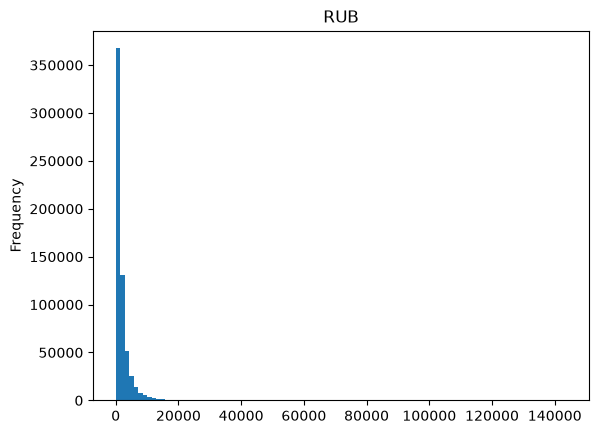

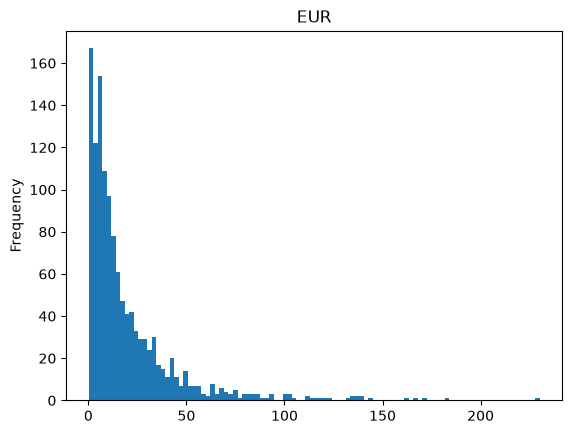

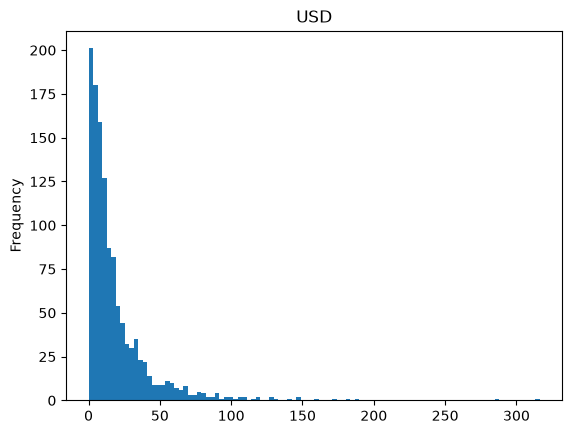

In [1056]:
txns_df['amount'] = txns_df['amount'].abs()
for currency in txns_df['currency'].unique():
    txns_df.loc[txns_df['currency'] == currency, 'amount'].plot.hist(bins=100, title=currency)
    plt.show()

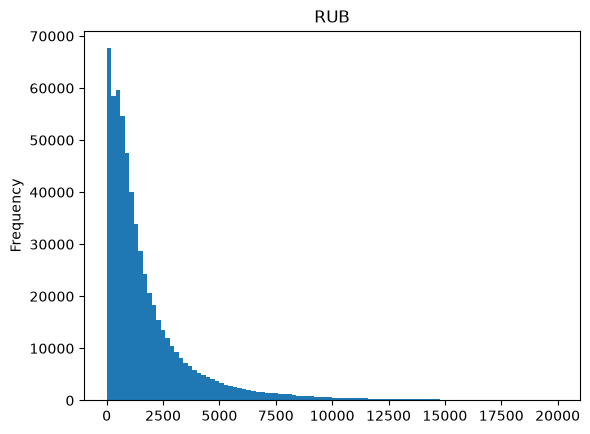

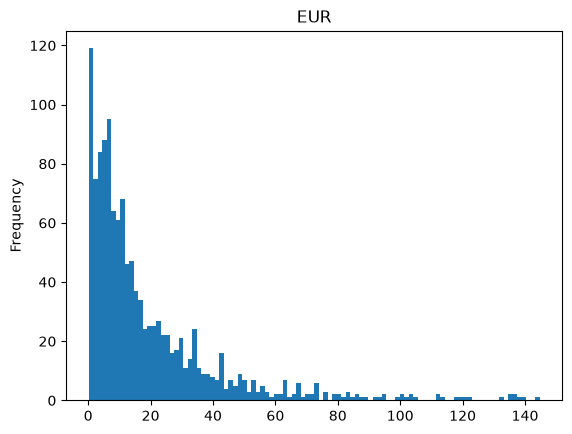

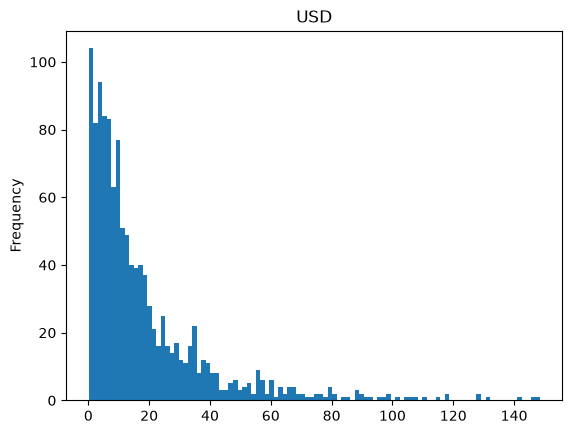

In [1057]:
for currency in txns_df['currency'].unique():
    if currency == 'RUB':
        boarder = 20_000
    else:
        boarder = 150
    txns_df.loc[(txns_df['currency'] == currency) & (txns_df['amount'] < boarder), 'amount'].plot.hist(bins=100, title=currency)
    plt.show()

In [1058]:
for currency in txns_df['currency'].unique():
    zero_count = txns_df.loc[(txns_df['currency'] == currency) & (txns_df['amount'] == 0)].shape[0]
    print(f'В валюте {currency} нулевых транзакций: {zero_count}')

В валюте RUB нулевых транзакций: 0
В валюте EUR нулевых транзакций: 0
В валюте USD нулевых транзакций: 0


In [1059]:
for currency in txns_df['currency'].unique():
    txns_df_box = txns_df.loc[txns_df['currency'] == currency]
    fig = px.box(txns_df_box, y='amount', title=currency)
    fig.show()

Нулевых и отрицательных транзакций нет. Максимальные суммы транзакций выглядят адекватно. Проверим их в разрезе категории трат

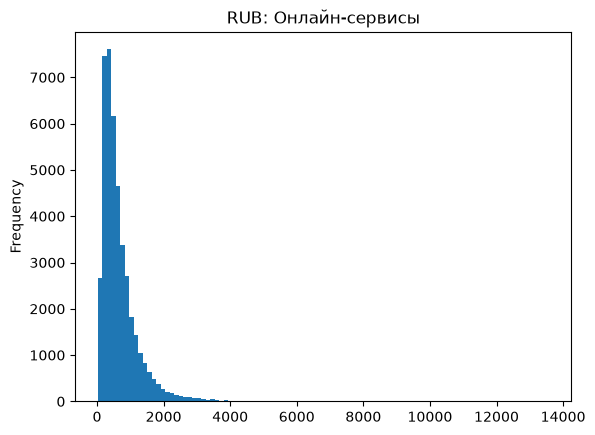

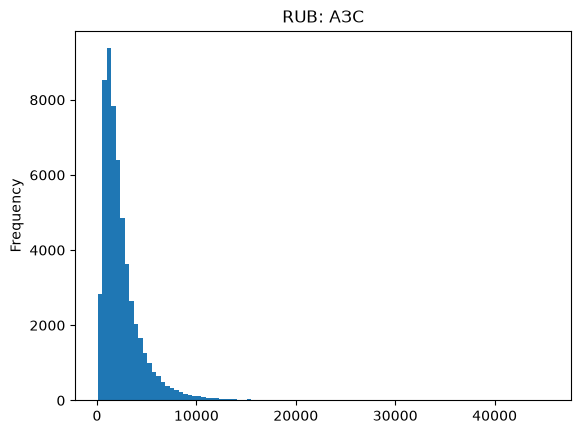

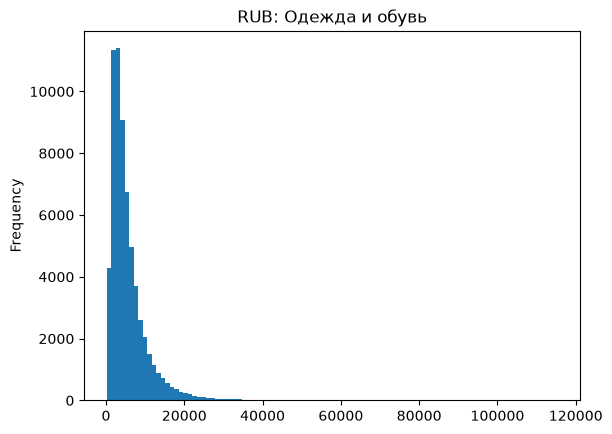

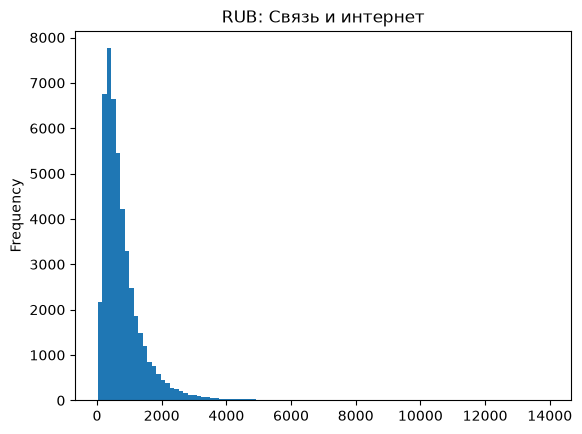

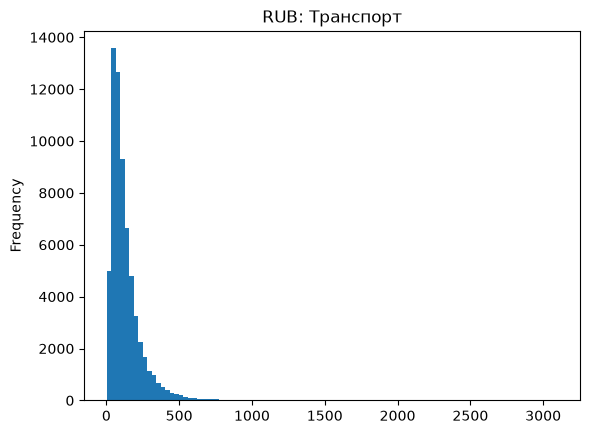

...

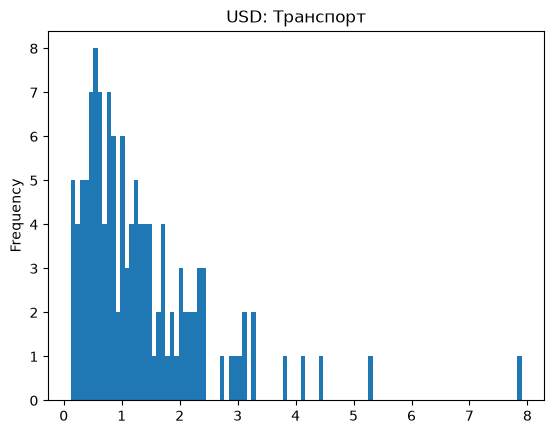

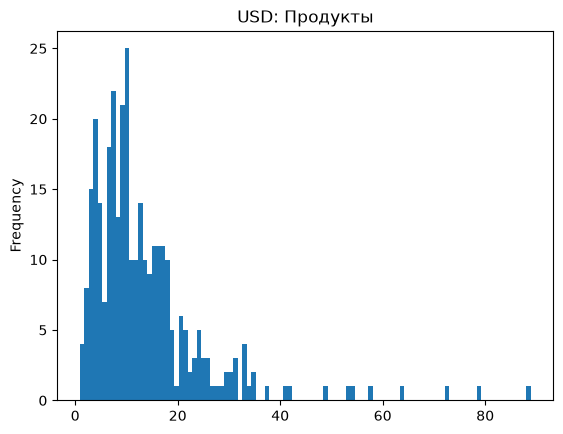

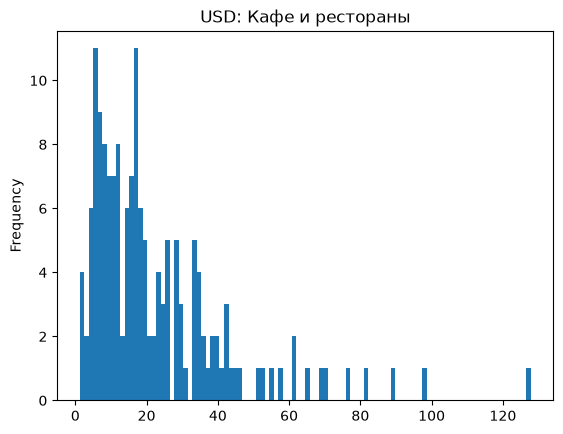

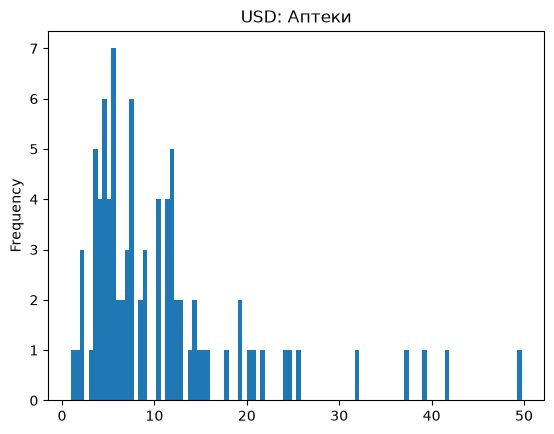

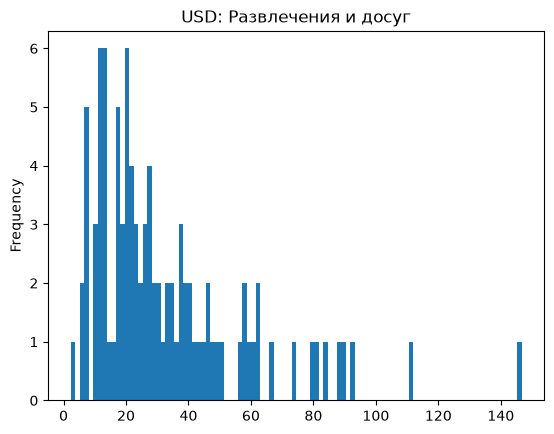

In [1060]:
for currency in txns_df['currency'].unique():
    for category in txns_df['category'].unique():
        txns_df.loc[(txns_df['currency'] == currency) & (txns_df['category'] == category), 'amount'].plot.hist(bins=100, title=f'{currency}: {category}')
        plt.show()

В валюте транзакции выглядят адекватно. А вот в рублях есть вопросы.

In [1061]:
for category in txns_df['category'].unique():
    txns_df_box = txns_df.loc[(txns_df['currency'] == 'RUB') & (txns_df['category'] == category)]
    fig = px.box(txns_df_box, y='amount', title=category)
    fig.show()

В целом в такие траты можно поверить. Даже в трату 143 тыс. рублей на развлечения и досуг. Оставляем без изменений.

### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [1062]:
start_len = txns_df.shape[0]

txns_df = txns_df.loc[txns_df['txn_datetime'] <= '2025-06-30']

finish_len = txns_df.shape[0]

print('Было строк: ', start_len)
print('Удалено строк: ', start_len - finish_len)
print('Удаленный процент: ', round(((start_len - finish_len) / start_len) * 100, 2))
print('Стало строк: ', finish_len)


Было строк:  616922
Удалено строк:  905
Удаленный процент:  0.15
Стало строк:  616017


In [1063]:
txns_df.pivot_table(index='category', columns='mcc_code', values='txn_id', aggfunc='count')

mcc_code,4111,4814,5411,5541,5651,5812,5815,5912,7832
category,,,,,,,,,
АЗС,16,17,17,56380,20,17,16,26,25
Аптеки,14,14,12,21,27,13,18,44719,13
Кафе и рестораны,27,22,33,21,24,79585,28,23,27
Одежда и обувь,17,15,16,19,63409,19,23,30,31
Онлайн-сервисы,14,10,11,19,19,20,42810,11,14
Продукты,54,60,161677,58,55,55,46,46,51
Развлечения и досуг,17,13,19,18,20,13,13,19,53245
Связь и интернет,24,48139,14,15,21,31,9,16,13
Транспорт,64403,23,23,26,27,19,23,13,17


In [1064]:
start_len = txns_df.shape[0]

right_category_code = {
    'АЗС': 5541,
    'Аптеки': 5912,
    'Кафе и рестораны': 5812,
    'Одежда и обувь': 5651,
    'Онлайн-сервисы': 5815,
    'Продукты': 5411,
    'Развлечения и досуг': 7832,
    'Связь и интернет': 4814,
    'Транспорт': 4111
}

for key, value in right_category_code.items():
    txns_df = txns_df.drop(txns_df[(txns_df['category'] == key) & (txns_df['mcc_code'] != value)].index)

finish_len = txns_df.shape[0]

print('Было строк: ', start_len)
print('Удалено строк: ', start_len - finish_len)
print('Удаленный процент: ', round(((start_len - finish_len) / start_len) * 100, 2))
print('Стало строк: ', finish_len)

Было строк:  616017
Удалено строк:  1650
Удаленный процент:  0.27
Стало строк:  614367


In [1065]:
txns_df.info()

<class 'pandas.DataFrame'>
Index: 614367 entries, 5 to 241812
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        614367 non-null  int64         
 1   client_id     614367 non-null  str           
 2   txn_datetime  614367 non-null  datetime64[us]
 3   amount        614367 non-null  float64       
 4   currency      614367 non-null  str           
 5   category      614367 non-null  str           
 6   mcc_code      614367 non-null  int64         
 7   channel       614367 non-null  str           
 8   status        614367 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(5)
memory usage: 46.9 MB


In [1066]:
txns_df.info()

<class 'pandas.DataFrame'>
Index: 614367 entries, 5 to 241812
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        614367 non-null  int64         
 1   client_id     614367 non-null  str           
 2   txn_datetime  614367 non-null  datetime64[us]
 3   amount        614367 non-null  float64       
 4   currency      614367 non-null  str           
 5   category      614367 non-null  str           
 6   mcc_code      614367 non-null  int64         
 7   channel       614367 non-null  str           
 8   status        614367 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(5)
memory usage: 46.9 MB


In [1067]:
txns_df.info()

<class 'pandas.DataFrame'>
Index: 614367 entries, 5 to 241812
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        614367 non-null  int64         
 1   client_id     614367 non-null  str           
 2   txn_datetime  614367 non-null  datetime64[us]
 3   amount        614367 non-null  float64       
 4   currency      614367 non-null  str           
 5   category      614367 non-null  str           
 6   mcc_code      614367 non-null  int64         
 7   channel       614367 non-null  str           
 8   status        614367 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(5)
memory usage: 46.9 MB


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [1068]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

In [1069]:
new_row_list = []

In [1070]:
new_row = pd.DataFrame({
    "field": ['gender'], 
    "issue": ['бинарный признак кодируется буквами'], 
    "scope": ['все строки'], 
    "n_rows": ['5666'],
    "value_before": ['Ж/М'], 
    "action": ['замена на числа'], 
    "value_after": ['0/1'], 
    "rationale": ['С 0 и 1 легче работать, чем со строками']

})
new_row_list.append(new_row)

In [1071]:
new_row = pd.DataFrame({
    "field": ['has_mobile_app'], 
    "issue": ['бинарный признак кодируется буквами'], 
    "scope": ['все строки'], 
    "n_rows": ['5666'],
    "value_before": ['Нет/Да'], 
    "action": ['замена на числа'], 
    "value_after": ['0/1'], 
    "rationale": ['С 0 и 1 легче работать, чем со строками']

})
new_row_list.append(new_row)

In [1072]:
new_row = pd.DataFrame({
    "field": ['marketing_opt_in'], 
    "issue": ['бинарный признак кодируется буквами'], 
    "scope": ['все строки'], 
    "n_rows": ['5666'],
    "value_before": ['Нет/Да'], 
    "action": ['замена на числа'], 
    "value_after": ['0/1'], 
    "rationale": ['С 0 и 1 легче работать, чем со строками']

})
new_row_list.append(new_row)

In [1073]:
new_row = pd.DataFrame({
    "field": ['city'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['170'],
    "value_before": [' москва'], 
    "action": ['нормализация'], 
    "value_after": ['Москва'], 
    "rationale": ['сверено со списком городов, смысл не меняется']

})
new_row_list.append(new_row)

In [1074]:
new_row = pd.DataFrame({
    "field": ['city'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['174'],
    "value_before": ['МОСКВА'], 
    "action": ['нормализация'], 
    "value_after": ['Москва'], 
    "rationale": ['сверено со списком городов, смысл не меняется']

})
new_row_list.append(new_row)

In [1075]:
new_row = pd.DataFrame({
    "field": ['city'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['198'],
    "value_before": ['г. Москва'], 
    "action": ['нормализация'], 
    "value_after": ['Москва'], 
    "rationale": ['сверено со списком городов, смысл не меняется']

})
new_row_list.append(new_row)

In [1076]:
new_row = pd.DataFrame({
    "field": ['city'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['115'],
    "value_before": ['ЕКАТЕРИНБУРГ'], 
    "action": ['нормализация'], 
    "value_after": ['Екатеринбург'], 
    "rationale": ['сверено со списком городов, смысл не меняется']

})
new_row_list.append(new_row)

In [1077]:
new_row = pd.DataFrame({
    "field": ['city'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['97'],
    "value_before": ['г.Екатеринбург'], 
    "action": ['нормализация'], 
    "value_after": ['Екатеринбург'], 
    "rationale": ['сверено со списком городов, смысл не меняется']

})
new_row_list.append(new_row)

In [1078]:
new_row = pd.DataFrame({
    "field": ['city'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['168'],
    "value_before": ['Н. Новгород'], 
    "action": ['нормализация'], 
    "value_after": ['Нижний Новгород'], 
    "rationale": ['сверено со списком городов, смысл не меняется']

})
new_row_list.append(new_row)

In [1079]:
new_row = pd.DataFrame({
    "field": ['city'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['119'],
    "value_before": ['СПб'], 
    "action": ['нормализация'], 
    "value_after": ['Санкт-Петербург'], 
    "rationale": ['сверено со списком городов, смысл не меняется']

})
new_row_list.append(new_row)

In [1080]:
new_row = pd.DataFrame({
    "field": ['city'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['79'],
    "value_before": ['Санкт Петербург'], 
    "action": ['нормализация'], 
    "value_after": ['Санкт-Петербург'], 
    "rationale": ['сверено со списком городов, смысл не меняется']

})
new_row_list.append(new_row)

In [1081]:
new_row = pd.DataFrame({
    "field": ['city'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['103'],
    "value_before": ['г. Санкт-Петербург'], 
    "action": ['нормализация'], 
    "value_after": ['Санкт-Петербург'], 
    "rationale": ['сверено со списком городов, смысл не меняется']

})
new_row_list.append(new_row)

In [1082]:
new_row = pd.DataFrame({
    "field": ['city'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['235'],
    "value_before": ['г. Новосибирск'], 
    "action": ['нормализация'], 
    "value_after": ['Новосибирск'], 
    "rationale": ['сверено со списком городов, смысл не меняется']

})
new_row_list.append(new_row)

In [1083]:
new_row = pd.DataFrame({
    "field": ['city'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['172'],
    "value_before": ['казань'], 
    "action": ['нормализация'], 
    "value_after": ['Казань'], 
    "rationale": ['сверено со списком городов, смысл не меняется']

})
new_row_list.append(new_row)

In [1084]:
new_row = pd.DataFrame({
    "field": ['category'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['16046'],
    "value_before": ['Кафе/рестораны'], 
    "action": ['нормализация'], 
    "value_after": ['Кафе и рестораны'], 
    "rationale": ['сверено со списком категорий, смысл не меняется']

})
new_row_list.append(new_row)

In [1085]:
new_row = pd.DataFrame({
    "field": ['category'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['16092'],
    "value_before": ['кафе и рестораны'], 
    "action": ['нормализация'], 
    "value_after": ['Кафе и рестораны'], 
    "rationale": ['сверено со списком категорий, смысл не меняется']

})
new_row_list.append(new_row)

In [1086]:
new_row = pd.DataFrame({
    "field": ['category'], 
    "issue": ['разнобой написания'], 
    "scope": ['все строки'], 
    "n_rows": ['19287'],
    "value_before": ['Связь и Интернет'], 
    "action": ['нормализация'], 
    "value_after": ['Связь и интернет'], 
    "rationale": ['сверено со списком категорий, смысл не меняется']

})
new_row_list.append(new_row)

In [1087]:
new_row = pd.DataFrame({
    "field": ['client_id'], 
    "issue": ['полные дубликаты строк таблицы клиентов'], 
    "scope": ['все строки'], 
    "n_rows": ['41'],
    "value_before": ['-'], 
    "action": ['удаление дублирующихся строк'], 
    "value_after": ['-'], 
    "rationale": ['в таблице клиентов не должно быть полных дубликатов строк по смыслу']

})
new_row_list.append(new_row)

In [1088]:
new_row = pd.DataFrame({
    "field": ['txn_id'], 
    "issue": ['полные дубликаты строк таблицы транзакций'], 
    "scope": ['все строки'], 
    "n_rows": ['1282'],
    "value_before": ['-'], 
    "action": ['удаление дублирующихся строк'], 
    "value_after": ['-'], 
    "rationale": ['в таблице транзакций не должно быть полных дубликатов строк по смыслу']

})
new_row_list.append(new_row)

In [1089]:
new_row = pd.DataFrame({
    "field": ['txn_id'], 
    "issue": ['дубликаты по полю txn_id таблицы транзакций'], 
    "scope": ['все строки'], 
    "n_rows": ['218'],
    "value_before": ['-'], 
    "action": ['удаление строк-дубликатов без времени транзакции'], 
    "value_after": ['-'], 
    "rationale": ['в таблице транзакций не должно быть дубликатов txn_id по смыслу. Сохранены строки с более полнымми данными']

})
new_row_list.append(new_row)

In [1090]:
new_row = pd.DataFrame({
    "field": ['age'], 
    "issue": ['Добавлено новое поле с возрастом клиента на 2025-06-30'], 
    "scope": ['все строки'], 
    "n_rows": ['5625 '],
    "value_before": ['-'], 
    "action": ['добавление нового поля'], 
    "value_after": ['Возраст, лет'], 
    "rationale": ['Вспомогательное поле']

})
new_row_list.append(new_row)

In [1091]:
new_row = pd.DataFrame({
    "field": ['registration_trunc_year'], 
    "issue": ['Добавлено новое поле с годом регистрации'], 
    "scope": ['все строки'], 
    "n_rows": ['5625 '],
    "value_before": ['-'], 
    "action": ['добавление нового поля'], 
    "value_after": ['Год регистрации'], 
    "rationale": ['Вспомогательное поле']

})
new_row_list.append(new_row)

In [1092]:
new_row = pd.DataFrame({
    "field": ['card_open_date_trunc_year'], 
    "issue": ['Добавлено новое поле с годом открытия текущей карты'], 
    "scope": ['все строки'], 
    "n_rows": ['5625 '],
    "value_before": ['-'], 
    "action": ['добавление нового поля'], 
    "value_after": ['Год открытия текущей карты'], 
    "rationale": ['Вспомогательное поле']

})
new_row_list.append(new_row)

In [1093]:
new_row = pd.DataFrame({
    "field": ['monthly_income_isnull'], 
    "issue": ['Добавлено новое поле с флагом наличия пропуска в monthly_income'], 
    "scope": ['все строки'], 
    "n_rows": ['5625 '],
    "value_before": ['-'], 
    "action": ['добавление нового поля'], 
    "value_after": ['0/1'], 
    "rationale": ['Вспомогательное поле']

})
new_row_list.append(new_row)

In [1094]:
new_row = pd.DataFrame({
    "field": ['app_last_login_isnull'], 
    "issue": ['Добавлено новое поле с флагом наличия пропуска в app_last_login'], 
    "scope": ['все строки'], 
    "n_rows": ['5625 '],
    "value_before": ['-'], 
    "action": ['добавление нового поля'], 
    "value_after": ['0/1'], 
    "rationale": ['Вспомогательное поле']

})
new_row_list.append(new_row)

In [1095]:
new_row = pd.DataFrame({
    "field": ['satisfaction_score_isnull'], 
    "issue": ['Добавлено новое поле с флагом наличия пропуска в satisfaction_score'], 
    "scope": ['все строки'], 
    "n_rows": ['5625 '],
    "value_before": ['-'], 
    "action": ['добавление нового поля'], 
    "value_after": ['0/1'], 
    "rationale": ['Вспомогательное поле']

})
new_row_list.append(new_row)

In [1096]:
new_row = pd.DataFrame({
    "field": ['monthly_income'], 
    "issue": ['пропуски'], 
    "scope": ['все строки'], 
    "n_rows": ['532 '],
    "value_before": ['-'], 
    "action": ['Решено заполнить медианным доходом для сочетания segment, loyalty_tier, card_type'], 
    "value_after": ['медиана по группам'], 
    "rationale": ['Эти три поля относительно неплохо делят клиентов на группы по доходу']

})
new_row_list.append(new_row)

In [1097]:
new_row = pd.DataFrame({
    "field": ['app_last_login'], 
    "issue": ['пропуски'], 
    "scope": ['все строки'], 
    "n_rows": ['2149'],
    "value_before": ['-'], 
    "action": ['Решено оставить как есть'], 
    "value_after": ['-'], 
    "rationale": ['Пропуск возникает при отсутствии у клиента приложения']

})
new_row_list.append(new_row)

In [1098]:
new_row = pd.DataFrame({
    "field": ['satisfaction_score'], 
    "issue": ['пропуски'], 
    "scope": ['все строки'], 
    "n_rows": ['3340'],
    "value_before": ['-'], 
    "action": ['Решено заполнить заглушкой 0'], 
    "value_after": ['-'], 
    "rationale": ['Заполняем заглушкой 0, для удобства анализа']

})
new_row_list.append(new_row)

In [1099]:
new_row = pd.DataFrame({
    "field": ['monthly_income'], 
    "issue": ['отрицательные и подозрительно низкие доходы'], 
    "scope": ['все строки'], 
    "n_rows": ['170'],
    "value_before": ['< 15_000'], 
    "action": ['Решено заполнить медианным доходом для сочетания segment, loyalty_tier, card_type'], 
    "value_after": ['медиана по группам'], 
    "rationale": ['Отрицательные и низкие значения в этом поле недопустимы по смыслу. Поля segment, loyalty_tier, card_type относительно неплохо делят клиентов на группы по доходу. ']

})
new_row_list.append(new_row)

In [1100]:
new_row = pd.DataFrame({
    "field": ['amount'], 
    "issue": ['отрицательные значения'], 
    "scope": ['все строки'], 
    "n_rows": ['7347'],
    "value_before": ['< 0'], 
    "action": ['взятие модуля'], 
    "value_after": ['модуль из значения'], 
    "rationale": ['Судя по данным, отрицательные значения `amount` невозможны']

})
new_row_list.append(new_row)

In [1101]:
new_row = pd.DataFrame({
    "field": ['txn_datetime'], 
    "issue": ['записи после 2025-06-30'], 
    "scope": ['все строки'], 
    "n_rows": ['905'],
    "value_before": ['> 2025-06-30'], 
    "action": ['удаление записей'], 
    "value_after": ['-'], 
    "rationale": ['Оцениваемый период до 2025-06-30. Так же данные клиентов актульны были на 2025-06-30']

})
new_row_list.append(new_row)

In [1102]:
new_row = pd.DataFrame({
    "field": ['mcc_code, category'], 
    "issue": ['несоответствие кода категории'], 
    "scope": ['все строки'], 
    "n_rows": ['1650'],
    "value_before": ['-'], 
    "action": ['удаление записей с несоответствие кода категории'], 
    "value_after": ['-'], 
    "rationale": ['Невозможно понять, что именно в записи неправильно - код или категория. Лучше удалить, так как востановить непльзя']

})
new_row_list.append(new_row)

In [1103]:
cleaning_log = pd.concat([cleaning_log, *new_row_list])

In [1104]:
cleaning_log

,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,gender,бинарный признак кодируется буквами,все строки,5666,Ж/М,замена на числа,0/1,"С 0 и 1 легче работать, чем со строками"
0,has_mobile_app,бинарный признак кодируется буквами,все строки,5666,Нет/Да,замена на числа,0/1,"С 0 и 1 легче работать, чем со строками"
0,marketing_opt_in,бинарный признак кодируется буквами,все строки,5666,Нет/Да,замена на числа,0/1,"С 0 и 1 легче работать, чем со строками"
0,city,разнобой написания,все строки,170,москва,нормализация,Москва,"сверено со списком городов, смысл не меняется"
0,city,разнобой написания,все строки,174,МОСКВА,нормализация,Москва,"сверено со списком городов, смысл не меняется"
0,city,разнобой написания,все строки,198,г. Москва,нормализация,Москва,"сверено со списком городов, смысл не меняется"
0,city,разнобой написания,все строки,115,ЕКАТЕРИНБУРГ,нормализация,Екатеринбург,"сверено со списком городов, смысл не меняется"
0,city,разнобой написания,все строки,97,г.Екатеринбург,нормализация,Екатеринбург,"сверено со списком городов, смысл не меняется"
0,city,разнобой написания,все строки,168,Н. Новгород,нормализация,Нижний Новгород,"сверено со списком городов, смысл не меняется"
0,city,разнобой написания,все строки,119,СПб,нормализация,Санкт-Петербург,"сверено со списком городов, смысл не меняется"


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

In [1105]:
clients_df.info()

<class 'pandas.DataFrame'>
Index: 5625 entries, 0 to 5665
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   client_id                  5625 non-null   str           
 1   birth_date                 5625 non-null   datetime64[us]
 2   gender                     5625 non-null   int64         
 3   city                       5625 non-null   str           
 4   segment                    5625 non-null   str           
 5   loyalty_tier               5625 non-null   str           
 6   card_type                  5625 non-null   str           
 7   registration_date          5625 non-null   datetime64[us]
 8   card_open_date             5625 non-null   datetime64[us]
 9   income_source              5625 non-null   str           
 10  monthly_income             5625 non-null   float64       
 11  has_mobile_app             5625 non-null   int64         
 12  app_last_login        

In [1106]:
txns_df.info()

<class 'pandas.DataFrame'>
Index: 614367 entries, 5 to 241812
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        614367 non-null  int64         
 1   client_id     614367 non-null  str           
 2   txn_datetime  614367 non-null  datetime64[us]
 3   amount        614367 non-null  float64       
 4   currency      614367 non-null  str           
 5   category      614367 non-null  str           
 6   mcc_code      614367 non-null  int64         
 7   channel       614367 non-null  str           
 8   status        614367 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(5)
memory usage: 46.9 MB


In [1107]:
numerical_features = clients_df.select_dtypes(include=['int64', 'float64']).columns

### 5.1. Распределения количественных признаков

In [1108]:
clients_df.describe()

,birth_date,gender,registration_date,card_open_date,monthly_income,has_mobile_app,app_last_login,satisfaction_score,marketing_opt_in,age,registration_trunc_year,card_open_date_trunc_year
count,5625,5625.000000,5625,5625,5625.000000,5625.000000,3490,5625.000000,5625.000000,5625.000000,5625,5625
mean,1971-11-24 15:42:35.520000,0.497244,2017-09-06 11:23:31.200000,2020-09-14 10:43:50.400000,97787.080640,0.620444,2024-09-19 01:32:00.687679,1.368889,0.882133,53.131200,2017-03-10 04:25:59.040000,2020-03-17 20:42:52.800000
min,1936-07-23 00:00:00,0.000000,2010-01-08 00:00:00,2016-01-01 00:00:00,15500.000000,0.000000,2024-01-01 00:00:00,0.000000,0.000000,21.000000,2010-01-01 00:00:00,2016-01-01 00:00:00
25%,1963-01-14 00:00:00,0.000000,2015-04-02 00:00:00,2018-04-08 00:00:00,57100.000000,0.000000,2024-05-01 00:00:00,0.000000,1.000000,43.000000,2015-01-01 00:00:00,2018-01-01 00:00:00
50%,1973-10-25 00:00:00,0.000000,2017-08-04 00:00:00,2020-08-30 00:00:00,73400.000000,1.000000,2024-10-01 00:00:00,0.000000,1.000000,51.000000,2017-01-01 00:00:00,2020-01-01 00:00:00
75%,1982-07-08 00:00:00,1.000000,2020-01-29 00:00:00,2023-01-06 00:00:00,109500.000000,1.000000,2025-02-01 00:00:00,3.000000,1.000000,62.000000,2020-01-01 00:00:00,2023-01-01 00:00:00
max,2003-08-28 00:00:00,1.000000,2025-04-27 00:00:00,2025-05-16 00:00:00,865400.000000,1.000000,2025-06-01 00:00:00,5.000000,1.000000,88.000000,2025-01-01 00:00:00,2025-01-01 00:00:00
std,NaN,0.500037,NaN,NaN,78637.005537,0.485319,NaN,1.863284,0.322479,14.128054,NaN,NaN


<Axes: ylabel='Frequency'>

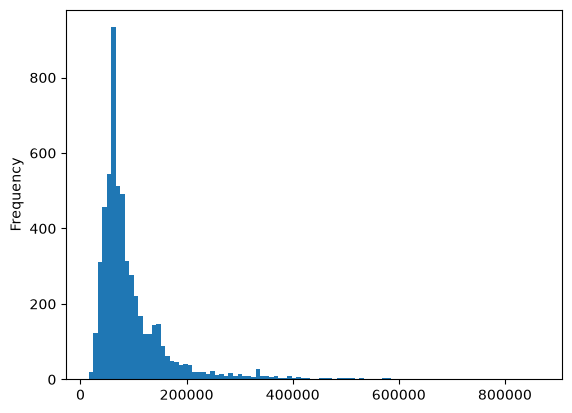

In [1109]:
clients_df['monthly_income'].plot.hist(bins=100)

In [1110]:
CONTINUOUS = ["monthly_income", 'age']


def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (s < q1 - k * iqr) | (s > q3 + k * iqr)

def make_dist_df(df, col_dict=CONTINUOUS):
    dist = pd.DataFrame({
        "skew": df[col_dict].apply(stats.skew),
        "kurtosis": df[col_dict].apply(stats.kurtosis),
        "Shapiro p-value": df[col_dict].apply(lambda s: stats.shapiro(s).pvalue),
        "выбросов по IQR": df[col_dict].apply(lambda s: iqr_outliers(s).sum()),
    })
    dist["нормальное (α=0.05)"] = dist["Shapiro p-value"] > 0.05
    dist["Shapiro p-value"] = dist["Shapiro p-value"].map("{:.1e}".format)
    dist = dist.round(3)
    return dist


In [1111]:
make_dist_df(clients_df)

c:\Users\Kuzuri\Python_projects\Lab1\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 5625.
  res = hypotest_fun_out(*samples, **kwds)


,skew,kurtosis,Shapiro p-value,выбросов по IQR,нормальное (α=0.05)
monthly_income,3.364,15.698,1.4e-74,456,False
age,0.559,-0.211,1.7e-33,0,False


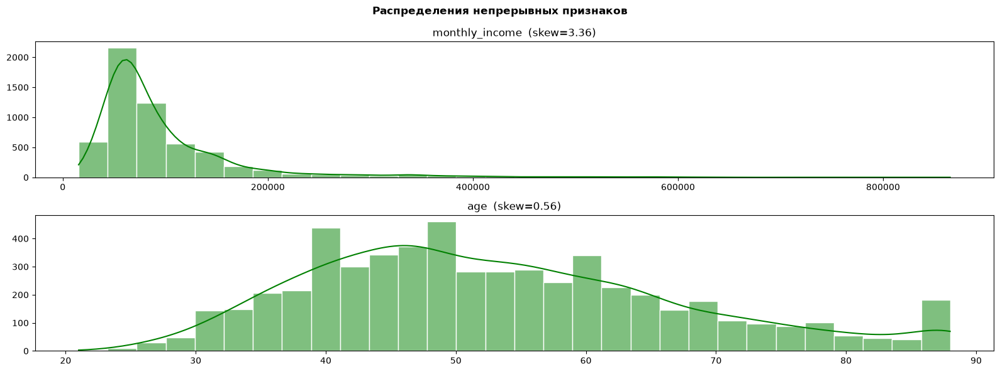

In [1112]:
fig, axes = plt.subplots(2, 1, figsize=(16, 6))
for ax, col in zip(axes.ravel(), CONTINUOUS):
    sns.histplot(
        clients_df[col], bins=30, kde=True, 
        ax=ax, color='green', edgecolor='white'
    )
    ax.set_title(f"{col}  (skew={stats.skew(clients_df[col]):.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Распределения непрерывных признаков", fontweight="bold")
plt.tight_layout()
plt.show()

Распределение не нормальное, с тяжелыми хвостами и скошеностью вправо.

In [1113]:
make_dist_df(txns_df, col_dict=['amount'])

c:\Users\Kuzuri\Python_projects\Lab1\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 614367.
  res = hypotest_fun_out(*samples, **kwds)


,skew,kurtosis,Shapiro p-value,выбросов по IQR,нормальное (α=0.05)
amount,5.526,78.953,1.9e-195,50247,False


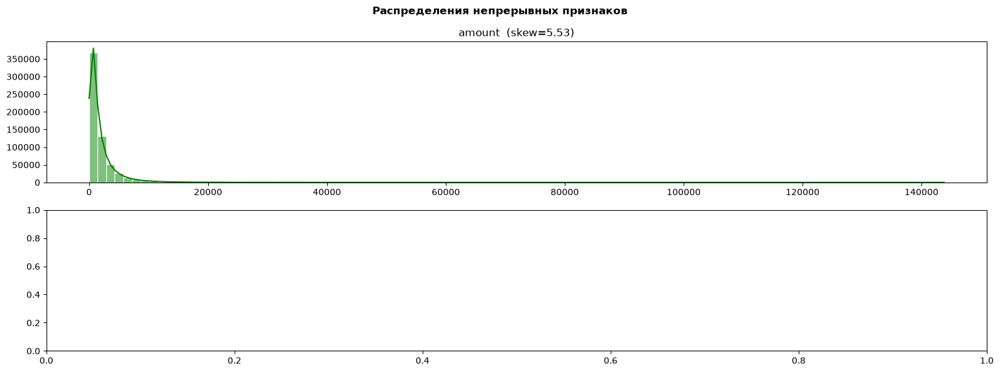

In [1114]:
fig, axes = plt.subplots(2, 1, figsize=(16, 6))
for ax, col in zip(axes.ravel(), ['amount']):
    sns.histplot(
        txns_df[col], bins=100, kde=True, 
        ax=ax, color='green', edgecolor='white'
    )
    ax.set_title(f"{col}  (skew={stats.skew(txns_df[col]):.2f})")
    ax.set_xlabel("")
    ax.set_ylabel("")
fig.suptitle("Распределения непрерывных признаков", fontweight="bold")
plt.tight_layout()
plt.show()

Распределение не нормальное, с тяжелыми хвостами и скошеностью вправо.

### 5.2. Частотные характеристики категориальных признаков

In [1115]:
clients_df.info()

<class 'pandas.DataFrame'>
Index: 5625 entries, 0 to 5665
Data columns (total 22 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   client_id                  5625 non-null   str           
 1   birth_date                 5625 non-null   datetime64[us]
 2   gender                     5625 non-null   int64         
 3   city                       5625 non-null   str           
 4   segment                    5625 non-null   str           
 5   loyalty_tier               5625 non-null   str           
 6   card_type                  5625 non-null   str           
 7   registration_date          5625 non-null   datetime64[us]
 8   card_open_date             5625 non-null   datetime64[us]
 9   income_source              5625 non-null   str           
 10  monthly_income             5625 non-null   float64       
 11  has_mobile_app             5625 non-null   int64         
 12  app_last_login        

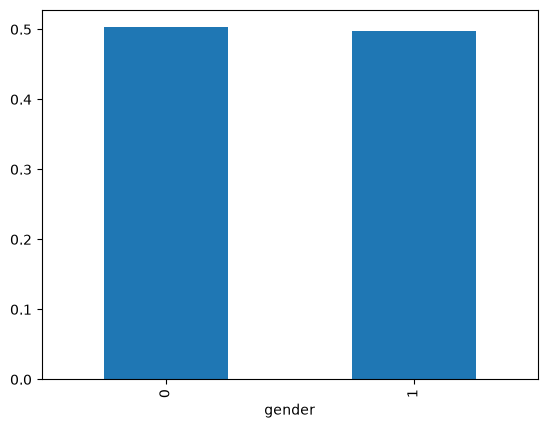

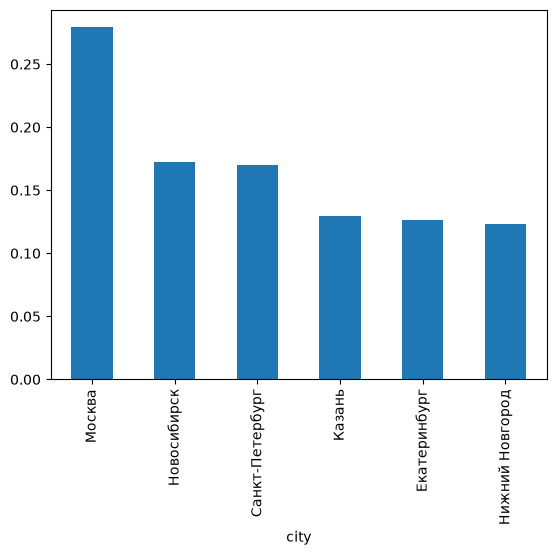

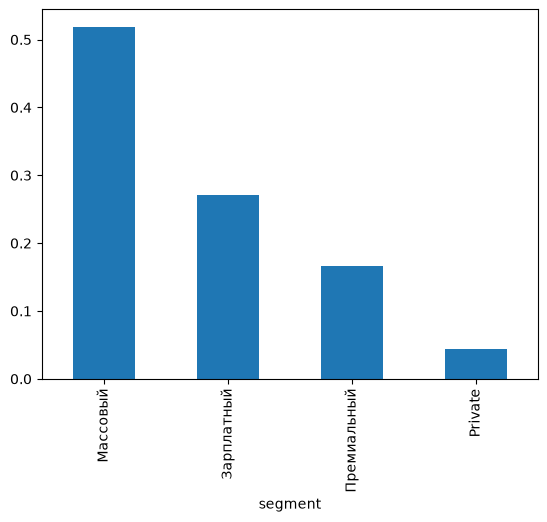

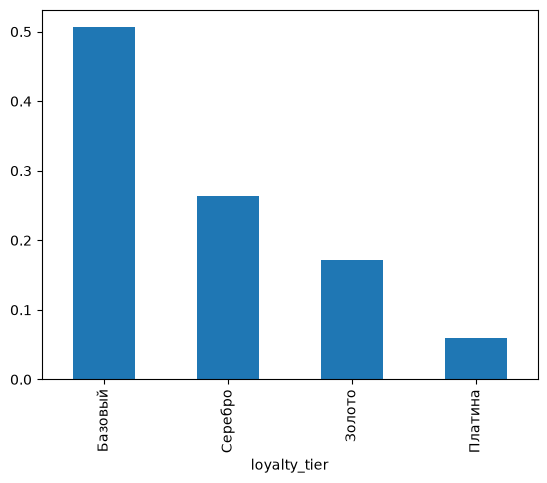

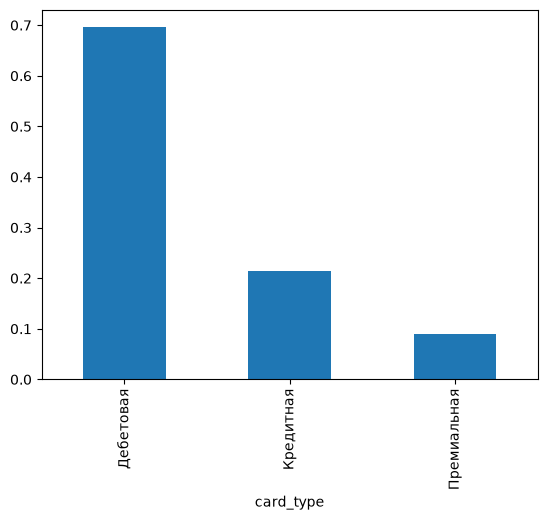

...

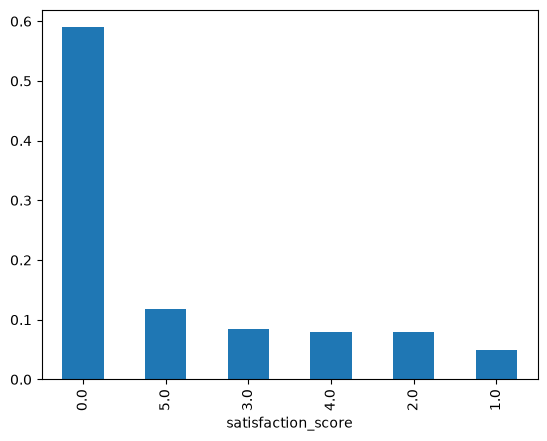

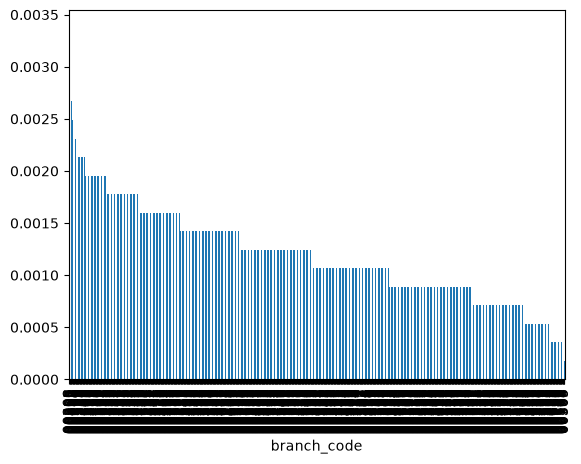

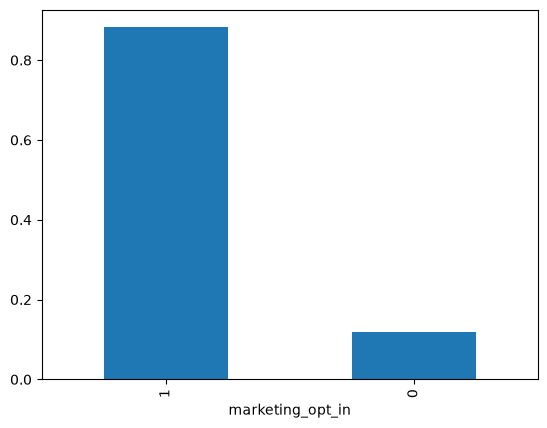

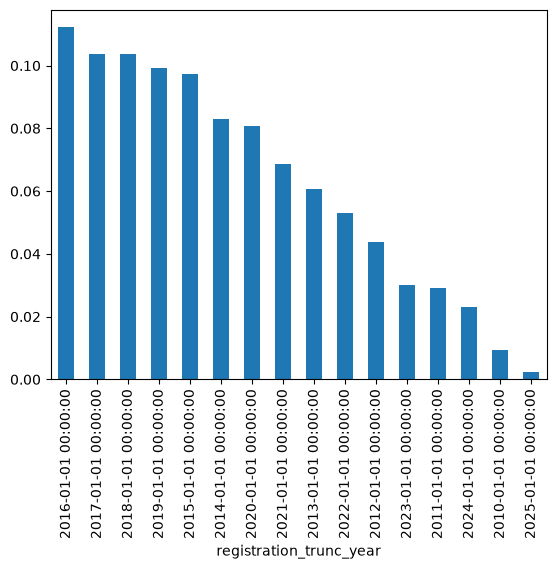

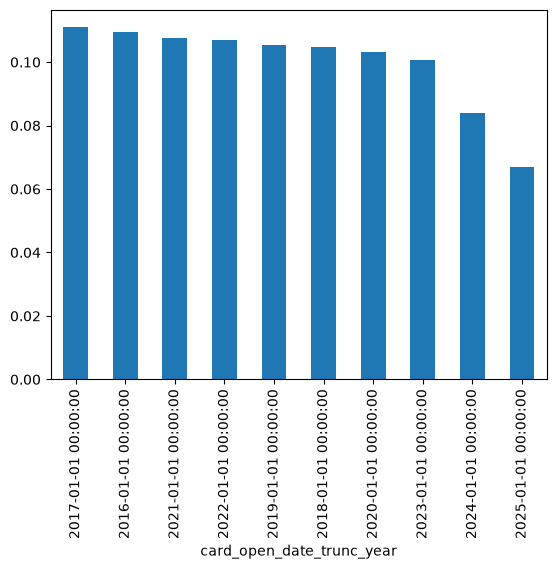

In [1116]:
category_cols = ['gender', 'city', 'segment', 'loyalty_tier', 'card_type', 
                 'income_source', 'has_mobile_app', 'satisfaction_score', 
                 'branch_code', 'marketing_opt_in', 'registration_trunc_year', 'card_open_date_trunc_year']

for col in category_cols:
    abs_cnts = clients_df[col].value_counts()
    rel_cnts = clients_df[col].value_counts(normalize=True)
    rows = clients_df[col].shape[0]
    plot_df = pd.DataFrame({'abs_cnts': abs_cnts, 'rel_cnts': rel_cnts, 'total': rows})

    plot_df['rel_cnts'].plot.bar()
    plt.show()
    

In [1117]:
txns_df.info()

<class 'pandas.DataFrame'>
Index: 614367 entries, 5 to 241812
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        614367 non-null  int64         
 1   client_id     614367 non-null  str           
 2   txn_datetime  614367 non-null  datetime64[us]
 3   amount        614367 non-null  float64       
 4   currency      614367 non-null  str           
 5   category      614367 non-null  str           
 6   mcc_code      614367 non-null  int64         
 7   channel       614367 non-null  str           
 8   status        614367 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(5)
memory usage: 46.9 MB


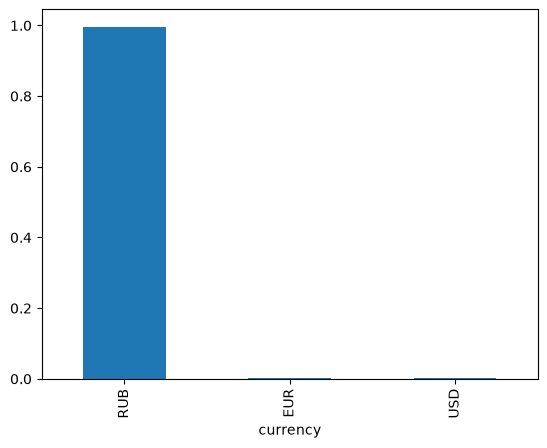

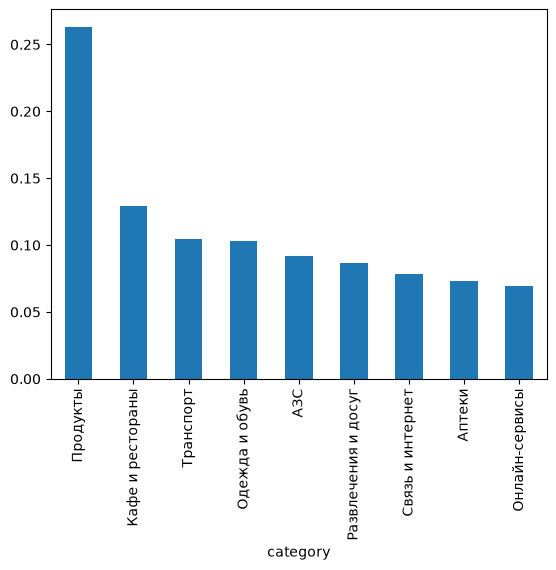

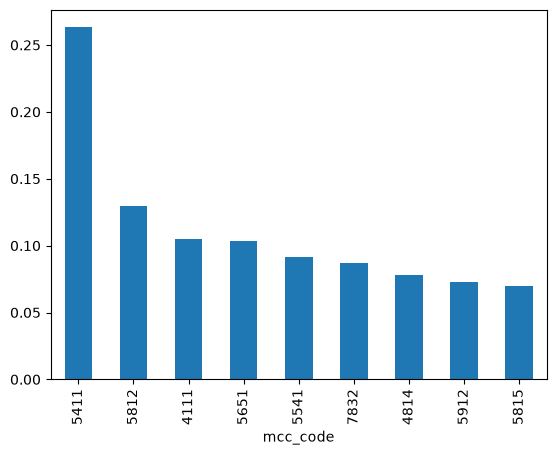

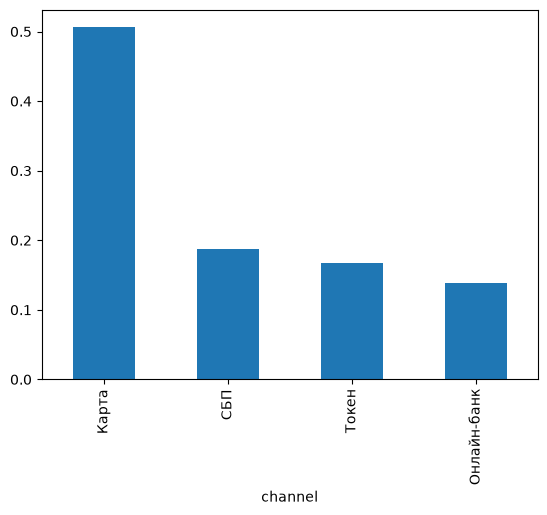

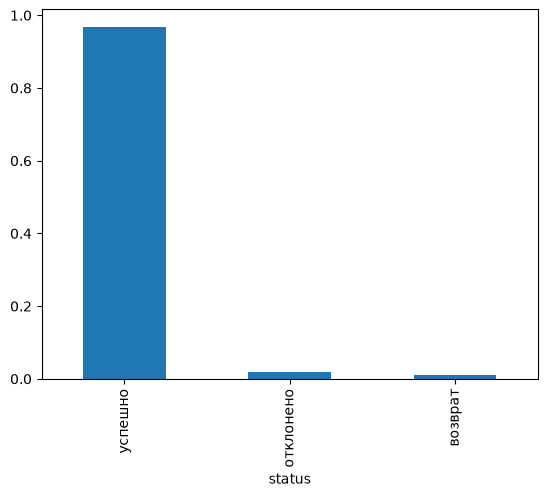

In [1118]:
category_cols = ['currency', 'category', 'mcc_code', 'channel', 'status']

for col in category_cols:
    abs_cnts = txns_df[col].value_counts()
    rel_cnts = txns_df[col].value_counts(normalize=True)
    rows = txns_df[col].shape[0]
    plot_df = pd.DataFrame({'abs_cnts': abs_cnts, 'rel_cnts': rel_cnts, 'total': rows})

    plot_df['rel_cnts'].plot.bar()
    plt.show()

### 5.3. Динамика по месяцам

In [1119]:
txns_time_series_df = txns_df.set_index('txn_datetime')
txns_time_series_df = txns_time_series_df.sort_index()
txns_time_series_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 614367 entries, 2023-12-03 07:08:38 to 2025-06-30 00:00:00
Data columns (total 8 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   txn_id     614367 non-null  int64  
 1   client_id  614367 non-null  str    
 2   amount     614367 non-null  float64
 3   currency   614367 non-null  str    
 4   category   614367 non-null  str    
 5   mcc_code   614367 non-null  int64  
 6   channel    614367 non-null  str    
 7   status     614367 non-null  str    
dtypes: float64(1), int64(2), str(5)
memory usage: 42.2 MB


In [1120]:
txns_time_series_df_month = txns_time_series_df.loc[txns_time_series_df['currency'] == 'RUB', 'amount'].resample('ME').agg(['sum', 'count', 'mean'])
txns_time_series_df_month

,sum,count,mean
txn_datetime,,,
2023-12-31,7820.61,5,1564.122000
2024-01-31,51314784.83,26240,1955.593934
2024-02-29,64019136.16,32830,1950.019377
2024-03-31,73425992.76,37631,1951.210246
2024-04-30,72542944.89,36712,1976.000896
2024-05-31,66292070.57,33643,1970.456576
2024-06-30,70622804.72,36309,1945.049567
2024-07-31,75294015.54,37722,1996.023953
2024-08-31,76719149.29,38864,1974.041511


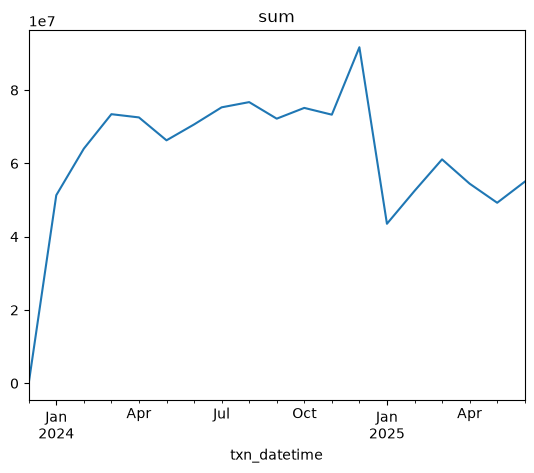

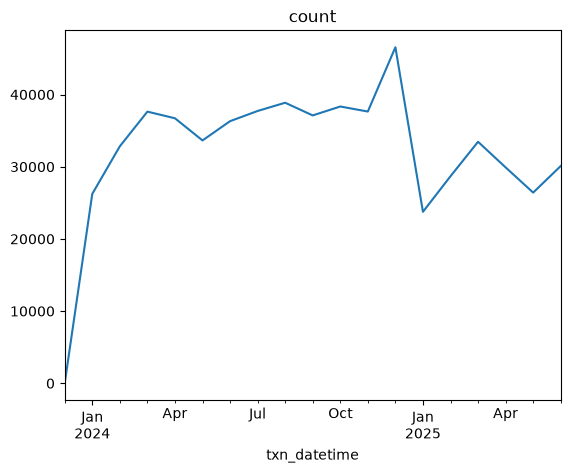

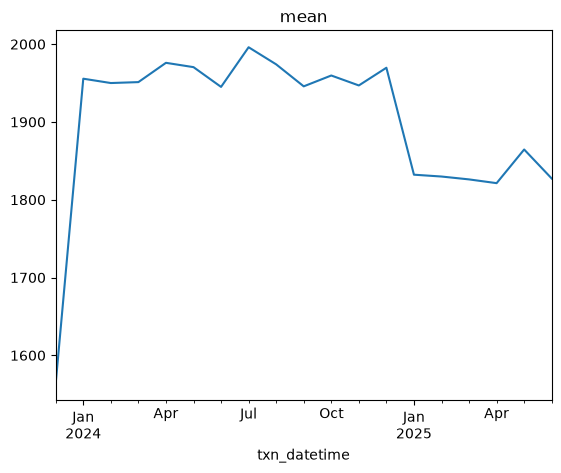

In [1121]:
for col in txns_time_series_df_month.columns:
    txns_time_series_df_month[col].plot(title=col)
    plt.show()

In [1122]:
vol_before = txns_time_series_df_month.loc['2024-01-01': '2024-06-30', 'sum'].mean()
vol_after = txns_time_series_df_month.loc['2025-01-01' : '2025-06-30', 'sum'].mean()
drop_pct = (vol_before - vol_after) / vol_before
print(f'Средний объем транзакций за период с 2024-01-01 по 2024-06-30 {vol_before:.2f}')
print(f'Средний объем транзакций за период с 2025-01-01 по 2025-06-30 {vol_after:.2f}')
print(f'Процент падения {drop_pct:.2%}')

Средний объем транзакций за период с 2024-01-01 по 2024-06-30 66369622.32
Средний объем транзакций за период с 2025-01-01 по 2025-06-30 52637011.02
Процент падения 20.69%


In [1123]:
vol_before - vol_after

np.float64(13732611.301666662)

По суммам, среднему размеру транзакции и их количеству наблюдается значительный дроп с января 2025 года. Нужно понять, засчет каких клиентов это происходит. Менее активными стали старые клиенты? Или меньше приходит новых клиентов?

### 5.4. Разрезы и связи между признаками

In [1124]:
txns_df.info()

<class 'pandas.DataFrame'>
Index: 614367 entries, 5 to 241812
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   txn_id        614367 non-null  int64         
 1   client_id     614367 non-null  str           
 2   txn_datetime  614367 non-null  datetime64[us]
 3   amount        614367 non-null  float64       
 4   currency      614367 non-null  str           
 5   category      614367 non-null  str           
 6   mcc_code      614367 non-null  int64         
 7   channel       614367 non-null  str           
 8   status        614367 non-null  str           
dtypes: datetime64[us](1), float64(1), int64(2), str(5)
memory usage: 46.9 MB


In [1125]:
txns_df_dummies = pd.get_dummies(txns_df, columns=['category', 'channel', 'status'])
txns_df_dummies['txn_datetime'] = txns_df_dummies['txn_datetime'].dt.to_period('M').dt.to_timestamp()
txns_df_dummies.head()

,txn_id,client_id,txn_datetime,amount,currency,mcc_code,category_АЗС,category_Аптеки,category_Кафе и рестораны,category_Одежда и обувь,category_Онлайн-сервисы,category_Продукты,category_Развлечения и досуг,category_Связь и интернет,category_Транспорт,channel_Карта,channel_Онлайн-банк,channel_СБП,channel_Токен,status_возврат,status_отклонено,status_успешно
5,100001,C003709,2024-01-01,195.47,RUB,5815,False,False,False,False,True,False,False,False,False,False,False,True,False,False,False,True
6,100002,C005936,2024-01-01,720.88,RUB,5541,True,False,False,False,False,False,False,False,False,False,False,False,True,False,False,True
7,100003,C004251,2024-01-01,4141.66,RUB,5651,False,False,False,True,False,False,False,False,False,True,False,False,False,False,False,True
8,100004,C002920,2024-01-01,231.65,RUB,4814,False,False,False,False,False,False,False,True,False,True,False,False,False,False,True,False
9,100005,C003500,2024-01-01,1382.87,RUB,5651,False,False,False,True,False,False,False,False,False,True,False,False,False,True,False,False


In [1126]:
txns_df_dummies = txns_df_dummies.drop(columns=['txn_id', 'mcc_code'])

In [1127]:
txns_df_grouped_by_clients_sum = txns_df_dummies.groupby(['client_id', 'txn_datetime', 'currency']).sum()
txns_df_grouped_by_clients_count = txns_df_dummies.groupby(['client_id', 'txn_datetime', 'currency'])['amount'].agg(['count', 'mean'])
txns_df_grouped_by_clients_count = txns_df_grouped_by_clients_count.rename(columns={'amount': 'count'})
txns_df_grouped = txns_df_grouped_by_clients_count.join(txns_df_grouped_by_clients_sum).reset_index()
txns_df_grouped.head()


,client_id,txn_datetime,currency,count,mean,amount,category_АЗС,category_Аптеки,category_Кафе и рестораны,category_Одежда и обувь,category_Онлайн-сервисы,category_Продукты,category_Развлечения и досуг,category_Связь и интернет,category_Транспорт,channel_Карта,channel_Онлайн-банк,channel_СБП,channel_Токен,status_возврат,status_отклонено,status_успешно
0,C000001,2024-01-01,RUB,4,488.452500,1953.81,0,2,0,0,0,1,0,0,1,0,3,0,1,0,0,4
1,C000001,2024-02-01,RUB,3,1485.223333,4455.67,0,0,0,2,0,0,0,1,0,3,0,0,0,0,0,3
2,C000001,2024-03-01,RUB,4,1750.070000,7000.28,1,0,0,1,0,1,0,1,0,1,1,1,1,0,0,4
3,C000001,2024-04-01,RUB,4,1861.240000,7444.96,0,0,0,0,0,3,1,0,0,0,0,2,2,0,0,4
4,C000001,2024-05-01,RUB,5,982.080000,4910.40,0,0,0,0,1,4,0,0,0,4,0,1,0,0,0,5


In [1128]:
txns_df_grouped.info()

<class 'pandas.DataFrame'>
RangeIndex: 94308 entries, 0 to 94307
Data columns (total 22 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   client_id                     94308 non-null  str           
 1   txn_datetime                  94308 non-null  datetime64[us]
 2   currency                      94308 non-null  str           
 3   count                         94308 non-null  int64         
 4   mean                          94308 non-null  float64       
 5   amount                        94308 non-null  float64       
 6   category_АЗС                  94308 non-null  int64         
 7   category_Аптеки               94308 non-null  int64         
 8   category_Кафе и рестораны     94308 non-null  int64         
 9   category_Одежда и обувь       94308 non-null  int64         
 10  category_Онлайн-сервисы       94308 non-null  int64         
 11  category_Продукты             94308 non

In [1129]:
full_df = clients_df.merge(txns_df_grouped, on='client_id', how='left')
full_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 89575 entries, 0 to 89574
Data columns (total 43 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   client_id                     89575 non-null  str           
 1   birth_date                    89575 non-null  datetime64[us]
 2   gender                        89575 non-null  int64         
 3   city                          89575 non-null  str           
 4   segment                       89575 non-null  str           
 5   loyalty_tier                  89575 non-null  str           
 6   card_type                     89575 non-null  str           
 7   registration_date             89575 non-null  datetime64[us]
 8   card_open_date                89575 non-null  datetime64[us]
 9   income_source                 89575 non-null  str           
 10  monthly_income                89575 non-null  float64       
 11  has_mobile_app                89575 non

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

Возьмем метрикой активности сумму транзакций по клиенту за месяц. Метрика грубая. Позволит увидеть объем транзакций (средняя сумма транзакций за месяц, умноженная на их количество). Метрика не позволит увидеть прямое снижение средней суммы транзакций или их количества. 

Так же можно проверить количество транзакций по категориям трат

Так же стоит проверить количество уникальных пользвователей по месяцам

Метрика: сравнение скользящего среднего объема транзакций пользователя за 3 месяца с его предыдущим скользящим средним за прошлый месяц - позволит найти пользвователей, чья активность упала

## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

In [1130]:
full_df_time_series = full_df.set_index('txn_datetime')
full_df = full_df.sort_values(by='txn_datetime')

In [1131]:
full_df['age_group'] = 'не определена'
full_df.loc[full_df['age'] < 20, 'age_group'] = 'младше 20 лет'
full_df.loc[(full_df['age'] >= 20) & (full_df['age'] < 30), 'age_group'] = '20-29 лет'
full_df.loc[(full_df['age'] >= 30) & (full_df['age'] < 40), 'age_group'] = '30-39 лет'
full_df.loc[(full_df['age'] >= 40) & (full_df['age'] < 50), 'age_group'] = '40-49 лет'
full_df.loc[(full_df['age'] >= 50) & (full_df['age'] < 60), 'age_group'] = '50-59 лет'
full_df.loc[(full_df['age'] >= 60) & (full_df['age'] < 70), 'age_group'] = '60-69 лет'
full_df.loc[full_df['age'] >= 70, 'age_group'] = 'старше 70 лет'

In [1132]:
for col in ['gender', 'age_group', 'segment', 'city',  'loyalty_tier', 'card_type', 'income_source', 'has_mobile_app', 'satisfaction_score', 'marketing_opt_in', 'registration_trunc_year', 'card_open_date_trunc_year']:
    df_for_plot = full_df.groupby(['txn_datetime', col])['amount'].mean().reset_index()
    fig = px.line(df_for_plot, x='txn_datetime', y='amount', color=col)
    fig.show()

In [1133]:
full_df.columns

Index(['client_id', 'birth_date', 'gender', 'city', 'segment', 'loyalty_tier', 'card_type', 'registration_date', 'card_open_date', 'income_source',
       'monthly_income', 'has_mobile_app', 'app_last_login', 'satisfaction_score', 'branch_code', 'marketing_opt_in', 'age', 'registration_trunc_year',
       'card_open_date_trunc_year', 'monthly_income_isnull', 'app_last_login_isnull', 'satisfaction_score_isnull', 'txn_datetime', 'currency', 'count', 'mean',
       'amount', 'category_АЗС', 'category_Аптеки', 'category_Кафе и рестораны', 'category_Одежда и обувь', 'category_Онлайн-сервисы', 'category_Продукты',
       'category_Развлечения и досуг', 'category_Связь и интернет', 'category_Транспорт', 'channel_Карта', 'channel_Онлайн-банк', 'channel_СБП',
       'channel_Токен', 'status_возврат', 'status_отклонено', 'status_успешно', 'age_group'],
      dtype='str')

In [1134]:
for col in ['category_АЗС', 'category_Аптеки', 'category_Кафе и рестораны', 'category_Одежда и обувь', 'category_Онлайн-сервисы', 'category_Продукты',
       'category_Развлечения и досуг', 'category_Связь и интернет', 'category_Транспорт']:
    df_for_plot = full_df.groupby('txn_datetime')[col].sum().reset_index()
    fig = px.line(df_for_plot, x='txn_datetime', y=col)
    fig.show()

In [1135]:
df_for_plot = full_df.groupby('txn_datetime')['client_id'].nunique().reset_index()
fig = px.line(df_for_plot, x='txn_datetime', y='client_id')
fig.show()

In [1136]:
for col in ['gender', 'age_group', 'segment', 'city',  'loyalty_tier', 'card_type', 'income_source', 'has_mobile_app', 'satisfaction_score', 'marketing_opt_in', 'registration_trunc_year', 'card_open_date_trunc_year']:
    df_for_plot = full_df.groupby(['txn_datetime', col])['client_id'].nunique().reset_index()
    fig = px.line(df_for_plot, x='txn_datetime', y='client_id', color=col)
    fig.show()

In [1137]:
full_df.info()

<class 'pandas.DataFrame'>
Index: 89575 entries, 14545 to 77454
Data columns (total 44 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   client_id                     89575 non-null  str           
 1   birth_date                    89575 non-null  datetime64[us]
 2   gender                        89575 non-null  int64         
 3   city                          89575 non-null  str           
 4   segment                       89575 non-null  str           
 5   loyalty_tier                  89575 non-null  str           
 6   card_type                     89575 non-null  str           
 7   registration_date             89575 non-null  datetime64[us]
 8   card_open_date                89575 non-null  datetime64[us]
 9   income_source                 89575 non-null  str           
 10  monthly_income                89575 non-null  float64       
 11  has_mobile_app                89575 non-

In [1138]:
df_filled_dates = (
    full_df.groupby(['client_id', 'txn_datetime'])['amount'].sum()
    .unstack(level=0, fill_value=0)
    .asfreq('ME', fill_value=0)
    .stack()
    .reset_index(name='amount')
    .sort_values(['client_id', 'txn_datetime'])
)

In [1139]:
df_filled_dates.head()

,txn_datetime,client_id,amount
0,2023-12-31,C000001,0.0
5602,2024-01-31,C000001,0.0
11204,2024-02-29,C000001,0.0
16806,2024-03-31,C000001,0.0
22408,2024-04-30,C000001,0.0


In [1140]:
df_filled_dates['rolling_mean_3'] = (
    df_filled_dates.groupby('client_id')['amount']
    .rolling(window=3, min_periods=1)  
    .mean()
    .reset_index(level=0, drop=True)
)

df_filled_dates.loc[df_filled_dates['client_id'] == 'C003454'].head()

,txn_datetime,client_id,amount,rolling_mean_3
3231,2023-12-31,C003454,0.0,0.0
8833,2024-01-31,C003454,0.0,0.0
14435,2024-02-29,C003454,0.0,0.0
20037,2024-03-31,C003454,0.0,0.0
25639,2024-04-30,C003454,0.0,0.0


### 7.1. Кого в кампанию не берём и почему

Анализ не завершен. Требуется разрешение от заказчика на проделие сроков работы

## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

Гипотеза: количество и объемы транзакций падают, так как количество уникальных пользователей в месяц упало - не подтвердилась

Гипотеза: падение объема транзакций связано с одним конкретным признаком - связь не установлена. Нужно искать комбинацию признаков.

## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [1141]:
full_df.to_parquet("clean_data.parquet", index=False)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
# campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")